In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


In [1]:
import qasp
from qasp import * 
import numpy as np
import torch 
import matplotlib.pyplot as plt


### Parity based policy training in cartpole-v1 environment

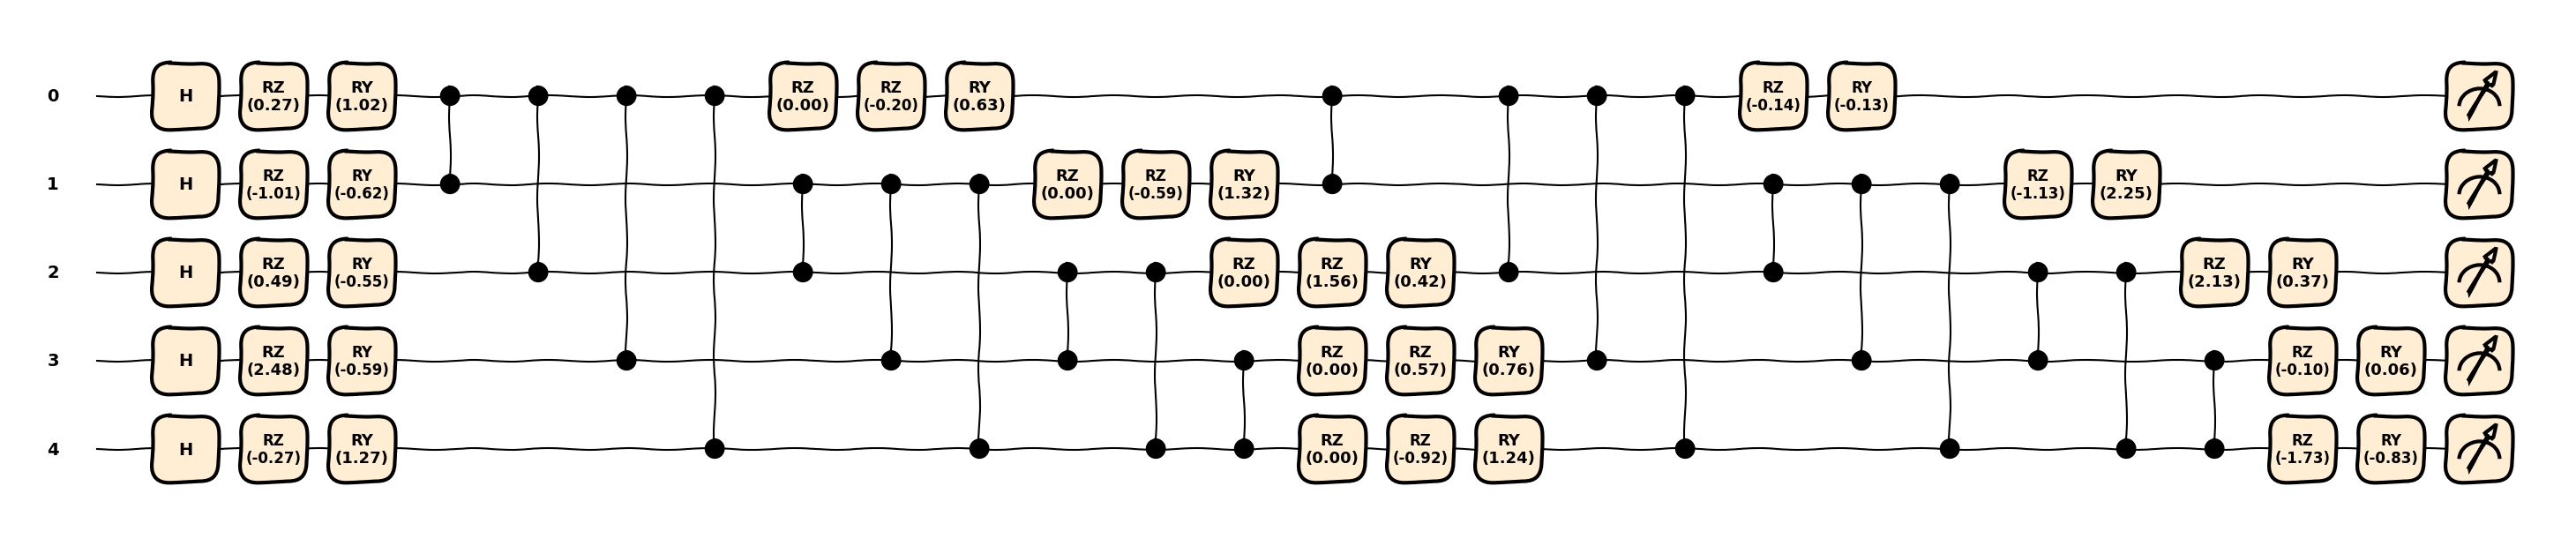

In [9]:
n_qubits = 5
fm_config = {
    "features": 4,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    #"shots": int(n_qubits**(2)),
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [10]:
agent = REINFORCE(
    policy=policy1,
    env_name="CartPole-v1",
    gamma=0.99,
    lr=1e-1,
    batch_episodes=5,
    logits=False,
    #normalize_mode="expand 10",
    normalize_mode="clip",
    normalize_returns=True,
    #entropy_coef=0.001,
    max_steps=200,
    baseline_type="ema",
    max_grad_norm=None,
)

r = agent.train(num_episodes=500)

Episode 0010 | avg(return_last20) = 11.2 | baseline = ema=5.5
Episode 0020 | avg(return_last20) = 15.4 | baseline = ema=7.2
Episode 0030 | avg(return_last20) = 22.9 | baseline = ema=9.2
Episode 0040 | avg(return_last20) = 30.9 | baseline = ema=11.5
Episode 0050 | avg(return_last20) = 37.5 | baseline = ema=13.3
Episode 0060 | avg(return_last20) = 52.8 | baseline = ema=18.6
Episode 0070 | avg(return_last20) = 92.2 | baseline = ema=27.6
Episode 0080 | avg(return_last20) = 134.7 | baseline = ema=35.6
Episode 0090 | avg(return_last20) = 149.7 | baseline = ema=40.2
Episode 0100 | avg(return_last20) = 167.4 | baseline = ema=46.2
Episode 0110 | avg(return_last20) = 189.7 | baseline = ema=50.1
Episode 0120 | avg(return_last20) = 188.2 | baseline = ema=51.7
Episode 0130 | avg(return_last20) = 188.8 | baseline = ema=53.5
Episode 0140 | avg(return_last20) = 192.2 | baseline = ema=54.3


KeyboardInterrupt: 

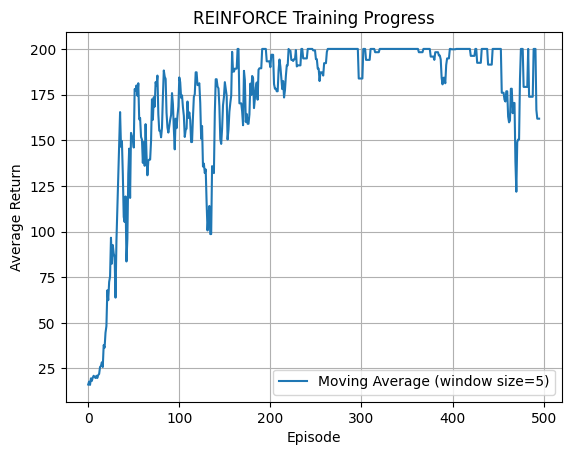

In [ ]:
#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(r, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size))
plt.xlabel('Episode')
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')

plt.legend()
plt.grid()
plt.show()



### majority modulo based policy training in cartpole-v1 environment

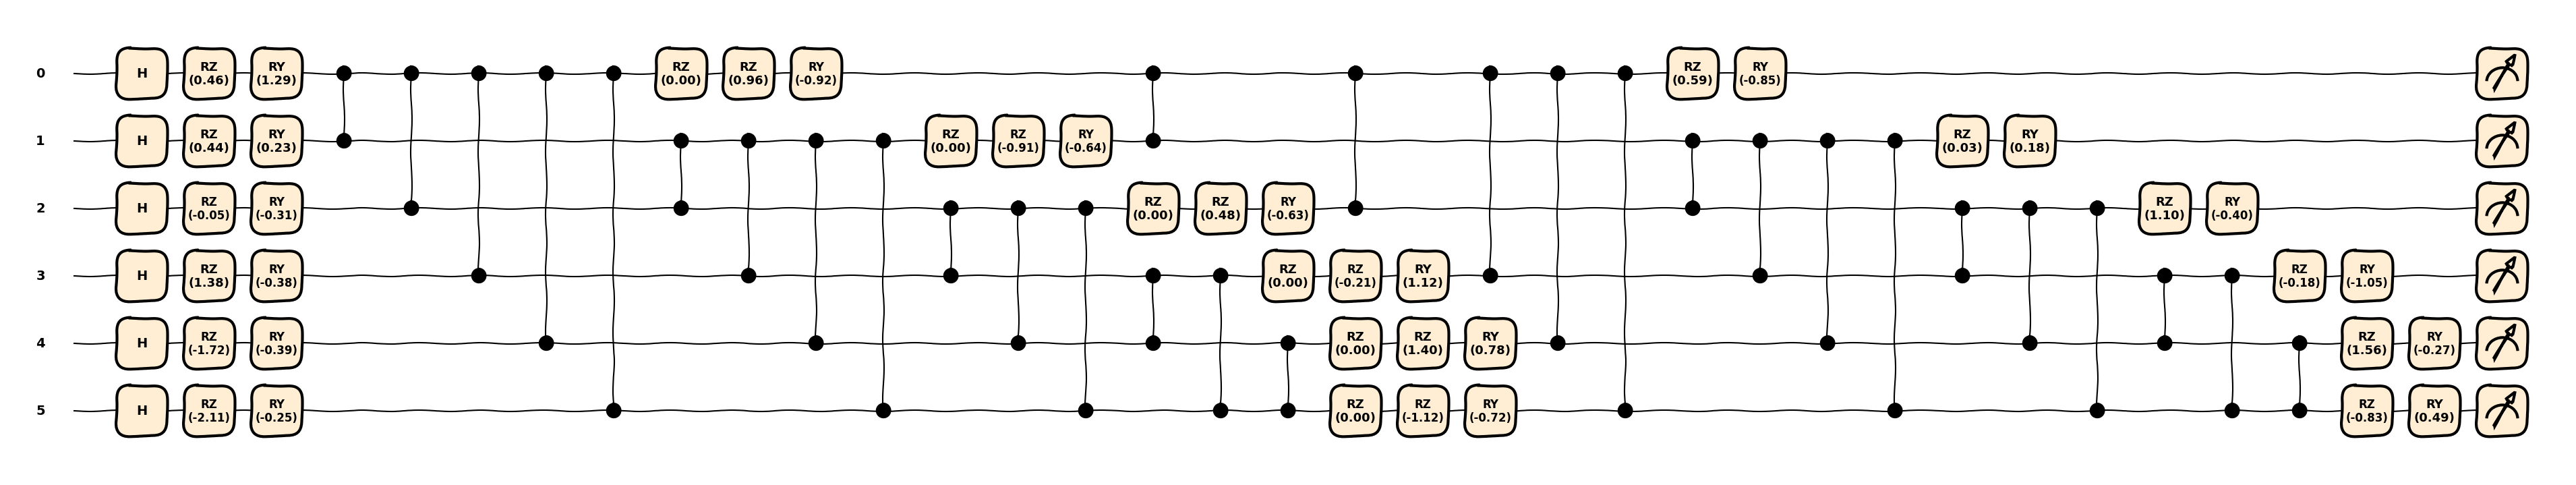

In [ ]:
n_qubits = 6
fm_config = {
    "features": 4,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "majority-modulo",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "sparse_projectors",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    #"shots": int(n_qubits**(2)),
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [5]:
agent = REINFORCE(
    policy=policy1,
    env_name="CartPole-v1",
    gamma=0.99,
    lr=1e-1,
    batch_episodes=5,
    logits=False,
    #normalize_mode="expand 10",
    normalize_mode="clip",
    normalize_returns=True,
    #entropy_coef=0.001,
    max_steps=200,
    baseline_type="ema",
    max_grad_norm=None,
)

r = agent.train(num_episodes=500)

Episode 0010 | avg(return_last20) = 14.5 | baseline = ema=7.3
Episode 0020 | avg(return_last20) = 15.9 | baseline = ema=7.9
Episode 0030 | avg(return_last20) = 17.1 | baseline = ema=8.1
Episode 0040 | avg(return_last20) = 18.9 | baseline = ema=9.0
Episode 0050 | avg(return_last20) = 21.7 | baseline = ema=9.7
Episode 0060 | avg(return_last20) = 24.1 | baseline = ema=10.6
Episode 0070 | avg(return_last20) = 30.1 | baseline = ema=12.4
Episode 0080 | avg(return_last20) = 36.1 | baseline = ema=14.2
Episode 0090 | avg(return_last20) = 49.1 | baseline = ema=18.2
Episode 0100 | avg(return_last20) = 65.5 | baseline = ema=22.2
Episode 0110 | avg(return_last20) = 79.2 | baseline = ema=26.2
Episode 0120 | avg(return_last20) = 101.0 | baseline = ema=31.3
Episode 0130 | avg(return_last20) = 135.3 | baseline = ema=37.6
Episode 0140 | avg(return_last20) = 153.7 | baseline = ema=41.7
Episode 0150 | avg(return_last20) = 149.8 | baseline = ema=43.3
Episode 0160 | avg(return_last20) = 159.9 | baseline = e

## Matched graph-IQP sweep: policy, initialization, and depth

This experiment compares parity and majority-modulo using **exactly matched graph-IQP circuits and initial trainable tensors**. For each depth $L\in\{1,2,3\}$, both policies are trained from five different random initializations. Within a `(layer, seed)` pair, the majority model receives an exact copy of the parity model's circuit and input-scaling parameters, so only the action readout changes. Five qubits allow a tie-free majority over every qubit. The connected ring graph retains bounded degree and therefore limits light-cone growth relative to an all-to-all graph.

In [2]:
# Shared graph-IQP sweep configuration
IQP_N_QUBITS = 5
IQP_N_ACTIONS = 2
IQP_DEVICE = "lightning.qubit"  # change to lightning.kokkos if preferred
IQP_EPISODES = 500
IQP_LAYERS = (1, 2, 3)
IQP_SEEDS = (3, 7, 11, 23, 37)

def make_matched_iqp_policies(n_layers, seed):
    """Create parity and majority models with identical trainable tensors."""
    feature_map_config = {
        "features": 4,
        "rotations": "Z",
    }
    ansatz_config = {
        "n_layers": int(n_layers),
        "imprimitive_pattern": "ring",
        "reuploading": True,
        "include_single_qubit": True,
    }
    common_config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": ansatz_config,
        "feature_map": "NeuralEmbedding",
        "feature_map_config": feature_map_config,
        "n_actions": IQP_N_ACTIONS,
        "init": "normal_0_1",
        "device": IQP_DEVICE,
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(range(IQP_N_QUBITS)),
        "parity_cnot_decomposition": False,
    }

    parity_config = {
        **common_config,
        "policy": "parity-like",
        "training_method": "expectation",
    }
    majority_config = {
        **common_config,
        "policy": "majority-modulo",
        "training_method": "sparse_projectors",
        "majority_blocks": [list(range(IQP_N_QUBITS))],
        "enable_mpi": False,
    }

    torch.manual_seed(seed)
    np.random.seed(seed)
    parity_policy = create_model(
        "PQCBorn", parity_config, n_qubits=IQP_N_QUBITS
    )

    torch.manual_seed(seed)
    np.random.seed(seed)
    majority_policy = create_model(
        "PQCBorn", majority_config, n_qubits=IQP_N_QUBITS
    )
    majority_policy.qlayer.load_state_dict(parity_policy.qlayer.state_dict())

    parity_parameters = dict(parity_policy.named_parameters())
    majority_parameters = dict(majority_policy.named_parameters())
    assert parity_parameters.keys() == majority_parameters.keys()
    assert all(
        torch.equal(parity_parameters[name], majority_parameters[name])
        for name in parity_parameters
    )
    return parity_policy, majority_policy


def print_matched_trainable_parameters(parity_policy, majority_policy, n_layers, seed):
    """Print both parameter sets and verify exact elementwise equality."""
    parity_parameters = {
        name: parameter.detach().cpu()
        for name, parameter in parity_policy.named_parameters()
        if parameter.requires_grad
    }
    majority_parameters = {
        name: parameter.detach().cpu()
        for name, parameter in majority_policy.named_parameters()
        if parameter.requires_grad
    }

    print(f"\n=== {n_layers} IQP layer(s), initialization seed={seed} ===")
    for name in parity_parameters:
        parity_tensor = parity_parameters[name]
        majority_tensor = majority_parameters[name]
        print(f"\n{name} | shape={tuple(parity_tensor.shape)}")
        print("Parity :", parity_tensor)
        print("Majority:", majority_tensor)
        print("Exactly identical:", torch.equal(parity_tensor, majority_tensor))

    parity_count = sum(t.numel() for t in parity_parameters.values())
    majority_count = sum(t.numel() for t in majority_parameters.values())
    print(f"Total trainable parameters: parity={parity_count}, majority={majority_count}")
    assert parity_count == majority_count


# Print a complete matched initialization for every circuit depth.
parameter_check_models = {}
for n_layers in IQP_LAYERS:
    parity_model, majority_model = make_matched_iqp_policies(
        n_layers=n_layers, seed=IQP_SEEDS[0]
    )
    parameter_check_models[n_layers] = (parity_model, majority_model)
    print_matched_trainable_parameters(
        parity_model, majority_model, n_layers=n_layers, seed=IQP_SEEDS[0]
    )
    zero_state = torch.zeros(4)
    print("Parity initial probabilities :", parity_model(zero_state))
    print("Majority initial probabilities:", majority_model(zero_state))


=== 1 IQP layer(s), initialization seed=3 ===

qlayer.input_scaling_params | shape=(20,)
Parity : tensor([-0.0766,  0.3599, -0.7820,  0.0715,  1.0460,  0.5222, -0.1668,  0.0530,
         0.4046,  0.6113,  0.7604, -0.0336,  0.9979,  0.4592,  2.4364, -0.1468,
         0.4851,  0.2052,  0.3384,  1.3528])
Majority: tensor([-0.0766,  0.3599, -0.7820,  0.0715,  1.0460,  0.5222, -0.1668,  0.0530,
         0.4046,  0.6113,  0.7604, -0.0336,  0.9979,  0.4592,  2.4364, -0.1468,
         0.4851,  0.2052,  0.3384,  1.3528])
Exactly identical: True

qlayer.params | shape=(10,)
Parity : tensor([ 0.4952, -0.1643, -0.6780, -1.0591,  0.7477,  0.2389, -0.3922,  0.1519,
        -1.1837,  0.5344])
Majority: tensor([ 0.4952, -0.1643, -0.6780, -1.0591,  0.7477,  0.2389, -0.3922,  0.1519,
        -1.1837,  0.5344])
Exactly identical: True
Total trainable parameters: parity=30, majority=30
Parity initial probabilities : tensor([0.6214, 0.3786], grad_fn=<ViewBackward0>)
Majority initial probabilities: tensor(

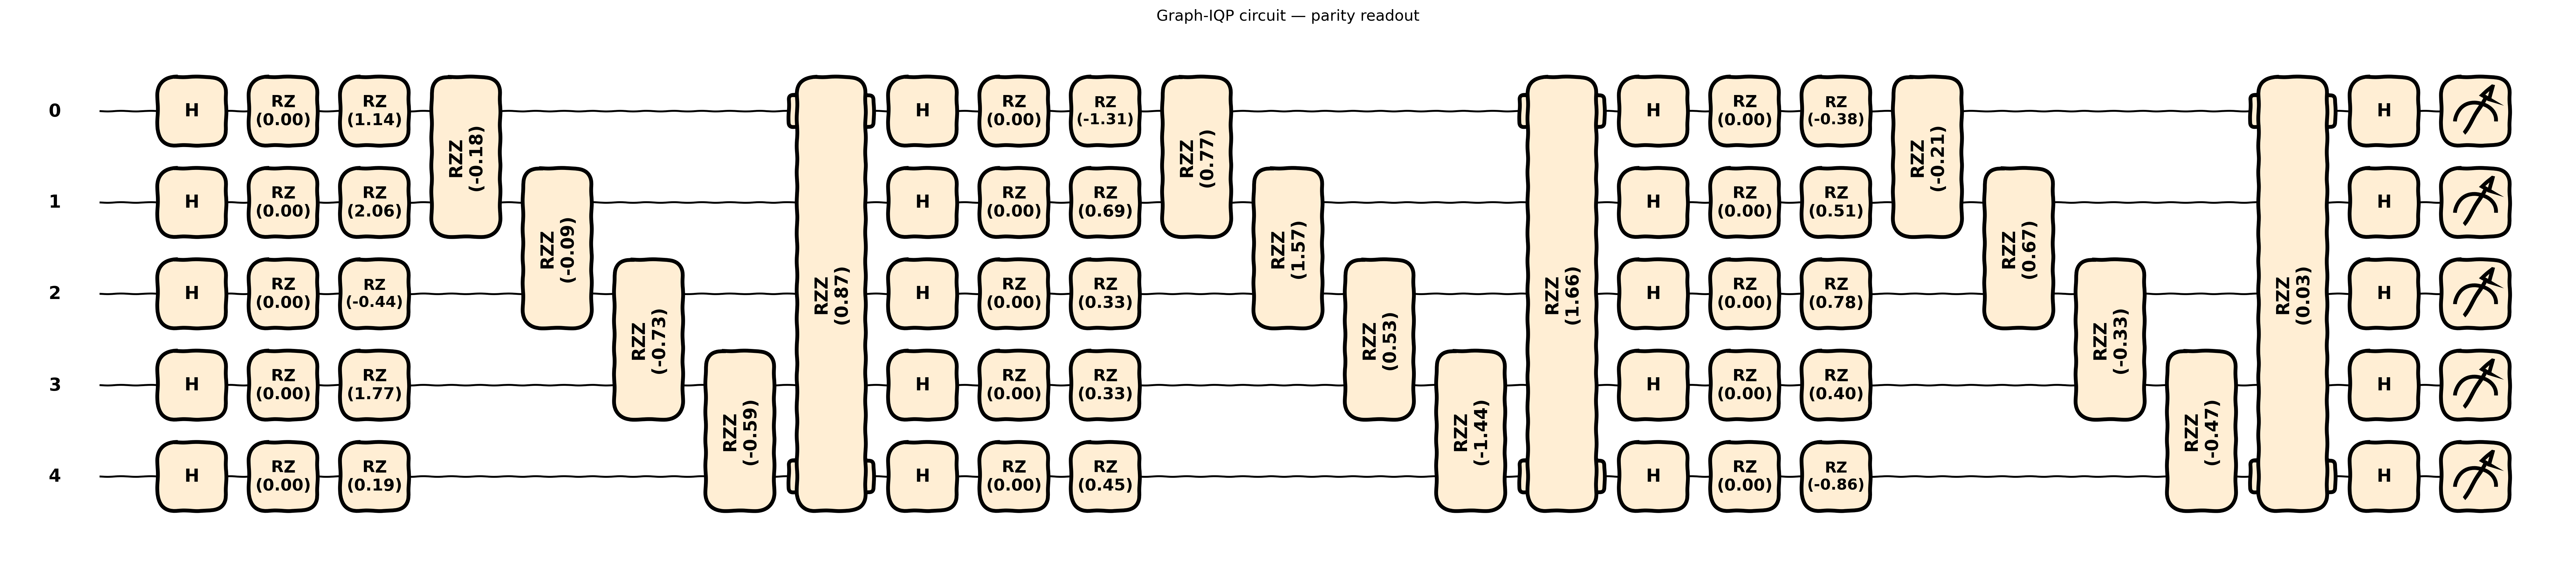

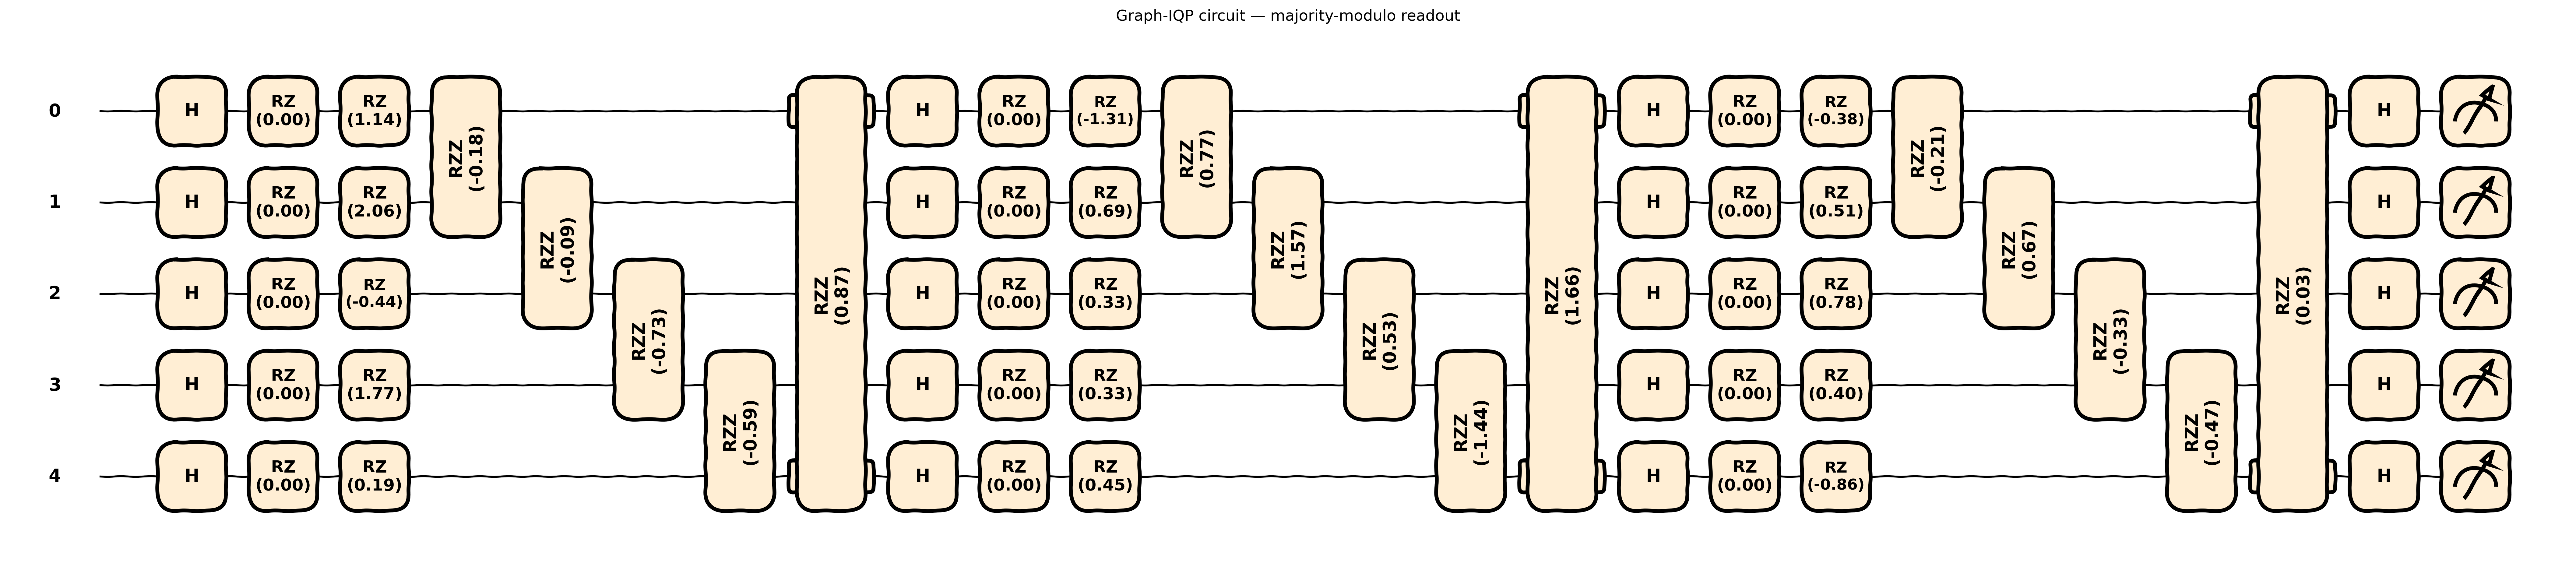

In [3]:
# Draw the deepest representative pair. Their gates and parameters match;
# only the final action observable differs.
parity_iqp_policy, majority_iqp_policy = parameter_check_models[3]

parity_fig, parity_ax = draw_model(
    model=parity_iqp_policy,
    policy_class="PQCBorn",
    n_qubits=IQP_N_QUBITS,
    num_inputs=4,
    inputs=torch.zeros(4),
)
parity_fig.set_dpi(300)
parity_fig.suptitle("Graph-IQP circuit — parity readout", y=1.02)
plt.show()

majority_fig, majority_ax = draw_model(
    model=majority_iqp_policy,
    policy_class="PQCBorn",
    n_qubits=IQP_N_QUBITS,
    num_inputs=4,
    inputs=torch.zeros(4),
)
majority_fig.set_dpi(300)
majority_fig.suptitle("Graph-IQP circuit — majority-modulo readout", y=1.02)
plt.show()

### Five-initialization CartPole sweep for 1, 2, and 3 layers

Every curve below is averaged over the five seeds in `IQP_SEEDS`. Each seed defines both the initial trainable parameters and the CartPole/action-sampling random streams. Within each seed, the two policies receive the same initial trainable tensors and the same environment seed. The trainer remains capped at 200 steps because its current solved criterion is an average return of 195. The three depth cells are separate so long experiments can be run and inspected incrementally.

In [4]:
import gc
import time


def make_iqp_cartpole_agent(policy, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    agent = REINFORCE(
        policy=policy,
        env_name="CartPole-v1",
        gamma=0.99,
        lr=3e-2,
        batch_episodes=5,
        logits=False,
        normalize_mode="clip",
        normalize_returns=True,
        entropy_coef=5e-3,
        max_steps=200,
        baseline_type="ema",
        baseline_momentum=0.05,
        max_grad_norm=1.0,
    )
    agent.env.reset(seed=seed)
    agent.env.action_space.seed(seed)
    return agent


def run_iqp_layer_sweep(n_layers, seeds=IQP_SEEDS, num_episodes=IQP_EPISODES):
    """Train both matched readouts for every initialization seed."""
    layer_results = {
        "parity": [],
        "majority": [],
        "parity_seconds": [],
        "majority_seconds": [],
    }

    for run_index, seed in enumerate(seeds, start=1):
        print(
            f"\n--- L={n_layers}, initialization {run_index}/{len(seeds)}, "
            f"seed={seed} ---"
        )
        parity_policy, majority_policy = make_matched_iqp_policies(
            n_layers=n_layers, seed=seed
        )
        parity_vector = torch.cat(
            [parameter.detach().flatten().cpu() for parameter in parity_policy.parameters()]
        )
        majority_vector = torch.cat(
            [parameter.detach().flatten().cpu() for parameter in majority_policy.parameters()]
        )
        print(
            "parameter check: "
            f"identical={torch.equal(parity_vector, majority_vector)}, "
            f"count={parity_vector.numel()}, L2={parity_vector.norm():.6f}, "
            f"first five={parity_vector[:5].tolist()}"
        )

        for policy_name, policy in (
            ("parity", parity_policy),
            ("majority", majority_policy),
        ):
            agent = make_iqp_cartpole_agent(policy, seed=seed)
            start = time.perf_counter()
            returns = agent.train(
                num_episodes=num_episodes, log_every=50
            )
            elapsed = time.perf_counter() - start
            agent.env.close()

            returns = np.asarray(returns, dtype=float)
            layer_results[policy_name].append(returns)
            layer_results[f"{policy_name}_seconds"].append(elapsed)
            print(
                f"{policy_name}: final-20 mean={returns[-20:].mean():.2f}, "
                f"time={elapsed:.1f}s"
            )

        del parity_policy, majority_policy
        gc.collect()

    layer_results["parity"] = np.stack(layer_results["parity"])
    layer_results["majority"] = np.stack(layer_results["majority"])
    return layer_results


iqp_sweep_results = {}

In [5]:
# Execute all five matched initializations for the 1-layer graph-IQP.
iqp_sweep_results[1] = run_iqp_layer_sweep(n_layers=1)


--- L=1, initialization 1/5, seed=3 ---
parameter check: identical=True, count=30, L2=4.121381, first five=[-0.07664430886507034, 0.35988152027130127, -0.7820167541503906, 0.07152773439884186, 1.046022891998291]
Episode 0050 | avg(return_last20) = 22.1 | baseline = ema=10.3
Episode 0100 | avg(return_last20) = 27.2 | baseline = ema=12.2
Episode 0150 | avg(return_last20) = 32.5 | baseline = ema=15.4
Episode 0200 | avg(return_last20) = 50.5 | baseline = ema=20.0
Episode 0250 | avg(return_last20) = 81.2 | baseline = ema=26.0
Episode 0300 | avg(return_last20) = 100.2 | baseline = ema=35.6
Episode 0350 | avg(return_last20) = 159.8 | baseline = ema=45.6
Episode 0400 | avg(return_last20) = 192.8 | baseline = ema=53.6
Episode 0450 | avg(return_last20) = 198.3 | baseline = ema=55.6
Episode 0500 | avg(return_last20) = 196.6 | baseline = ema=56.1
parity: final-20 mean=196.60, time=209.4s
Episode 0050 | avg(return_last20) = 12.8 | baseline = ema=6.4
Episode 0100 | avg(return_last20) = 14.4 | basel

In [6]:

# Execute all five matched initializations for the 2-layer graph-IQP.
iqp_sweep_results[2] = run_iqp_layer_sweep(n_layers=2)


--- L=2, initialization 1/5, seed=3 ---
parameter check: identical=True, count=60, L2=6.610683, first five=[-0.07664430886507034, 0.35988152027130127, -0.7820167541503906, 0.07152773439884186, 0.6648394465446472]
Episode 0050 | avg(return_last20) = 21.8 | baseline = ema=10.5
Episode 0100 | avg(return_last20) = 33.4 | baseline = ema=14.4
Episode 0150 | avg(return_last20) = 88.2 | baseline = ema=28.2
Episode 0200 | avg(return_last20) = 143.3 | baseline = ema=40.6
Episode 0250 | avg(return_last20) = 143.1 | baseline = ema=46.4
Episode 0300 | avg(return_last20) = 155.2 | baseline = ema=47.9
Episode 0350 | avg(return_last20) = 180.2 | baseline = ema=52.9
Episode 0400 | avg(return_last20) = 180.2 | baseline = ema=54.3
Episode 0450 | avg(return_last20) = 195.0 | baseline = ema=55.9
CartPole solved! Average return: 196.09. Stopping optimization.
Episode 0500 | avg(return_last20) = 200.0 | baseline = ema=57.0
parity: final-20 mean=200.00, time=368.1s
Episode 0050 | avg(return_last20) = 32.4 | 

In [7]:
# Execute all five matched initializations for the 3-layer graph-IQP.
iqp_sweep_results[3] = run_iqp_layer_sweep(n_layers=3)


--- L=3, initialization 1/5, seed=3 ---
parameter check: identical=True, count=90, L2=8.095360, first five=[-0.07664430886507034, 0.35988152027130127, -0.7820167541503906, 0.07152773439884186, 0.6648394465446472]
Episode 0050 | avg(return_last20) = 22.8 | baseline = ema=10.7
Episode 0100 | avg(return_last20) = 66.2 | baseline = ema=23.0
Episode 0150 | avg(return_last20) = 88.2 | baseline = ema=30.2
Episode 0200 | avg(return_last20) = 112.5 | baseline = ema=36.7
Episode 0250 | avg(return_last20) = 105.8 | baseline = ema=36.5
Episode 0300 | avg(return_last20) = 138.8 | baseline = ema=42.9
Episode 0350 | avg(return_last20) = 136.8 | baseline = ema=43.5
Episode 0400 | avg(return_last20) = 152.1 | baseline = ema=46.0
Episode 0450 | avg(return_last20) = 177.5 | baseline = ema=52.4
Episode 0500 | avg(return_last20) = 188.8 | baseline = ema=55.1
parity: final-20 mean=188.75, time=384.4s
Episode 0050 | avg(return_last20) = 54.2 | baseline = ema=19.1
Episode 0100 | avg(return_last20) = 135.7 | 

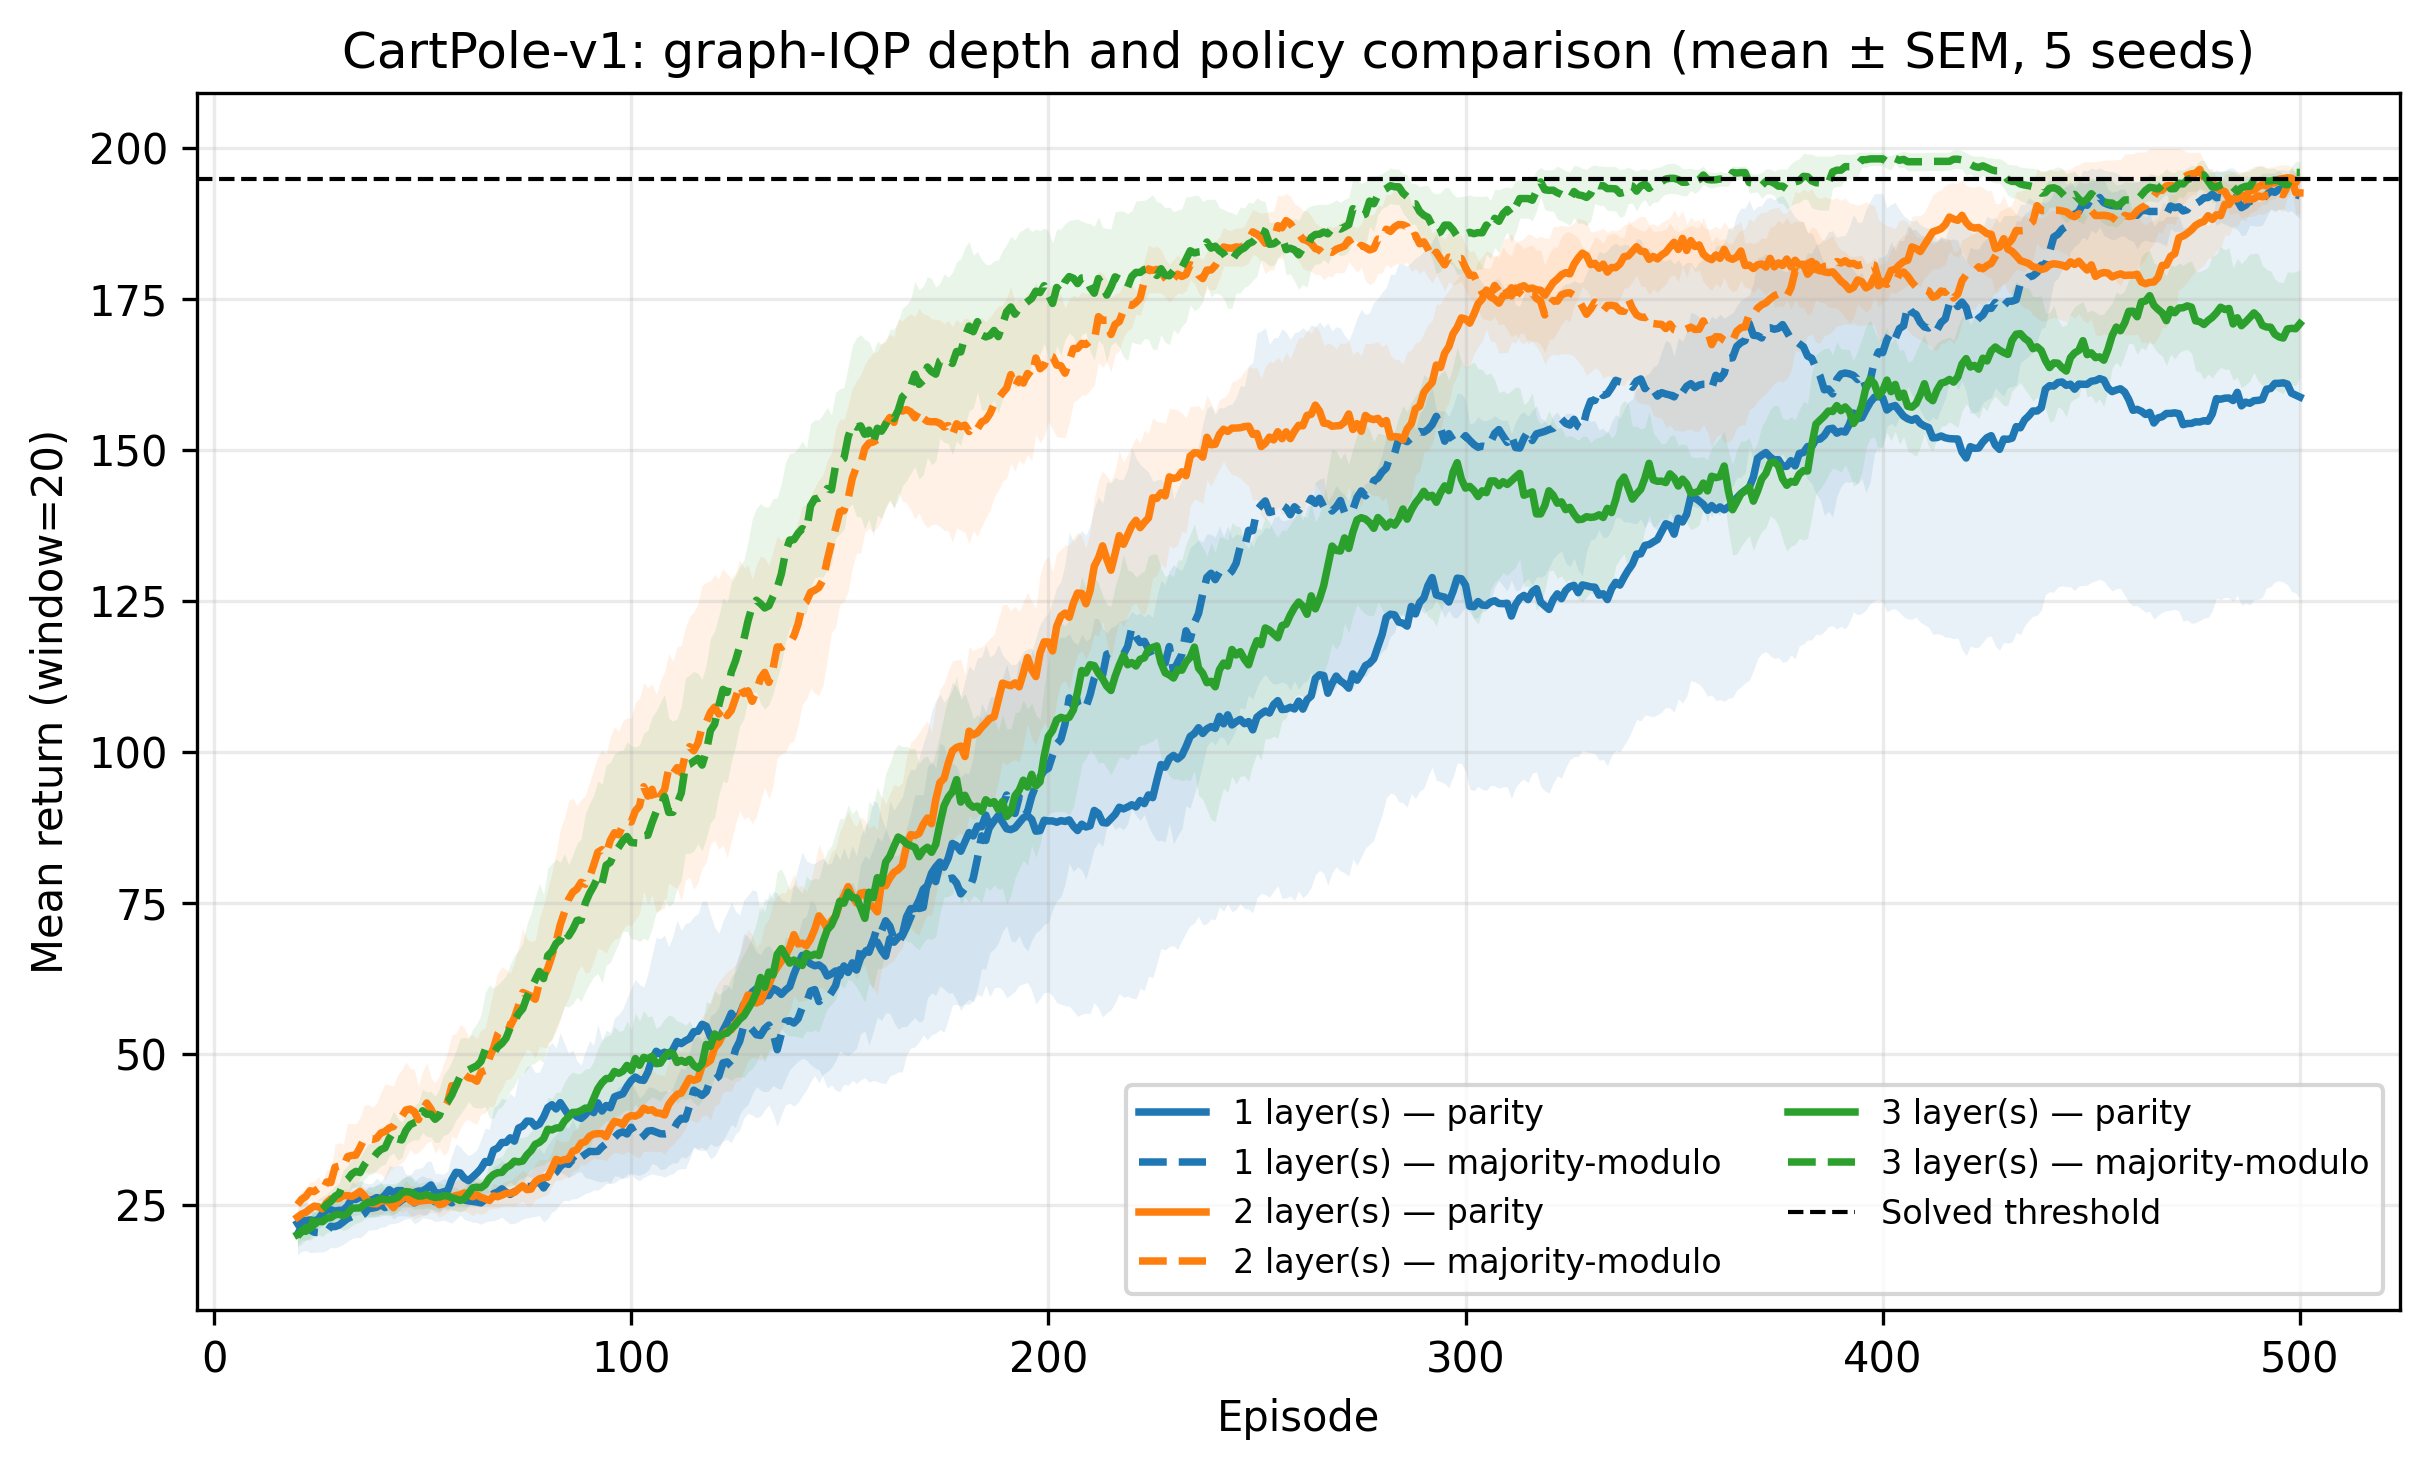

,layers,policy,mean_final_50,sem_final_50,mean_seconds,n_initializations
1,1,majority-modulo,191.280,3.852,244.094,5
0,1,parity,157.856,32.853,217.354,5
3,2,majority-modulo,193.656,2.193,389.257,5
2,2,parity,188.504,5.506,318.453,5
5,3,majority-modulo,194.524,1.885,587.654,5
4,3,parity,172.120,8.212,403.771,5


In [8]:
# Joint matched learning-curve comparison: mean over five initializations.
import pandas as pd
from IPython.display import display

missing_layers = set(IQP_LAYERS) - set(iqp_sweep_results)
if missing_layers:
    raise RuntimeError(
        f"Run the sweep cells for layers {sorted(missing_layers)} before plotting."
    )

comparison_window = 20
layer_colors = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}
policy_styles = {"parity": "-", "majority": "--"}
policy_labels = {"parity": "parity", "majority": "majority-modulo"}

fig, ax = plt.subplots(figsize=(8.2, 5.0), dpi=300)
summary_rows = []

for n_layers in IQP_LAYERS:
    result = iqp_sweep_results[n_layers]
    for policy_name in ("parity", "majority"):
        raw_runs = result[policy_name]
        smoothed_runs = np.stack(
            [
                np.convolve(
                    run,
                    np.ones(comparison_window) / comparison_window,
                    mode="valid",
                )
                for run in raw_runs
            ]
        )
        mean_curve = smoothed_runs.mean(axis=0)
        sem_curve = smoothed_runs.std(axis=0, ddof=1) / np.sqrt(len(raw_runs))
        episodes = np.arange(comparison_window, raw_runs.shape[1] + 1)
        color = layer_colors[n_layers]

        ax.plot(
            episodes,
            mean_curve,
            color=color,
            linestyle=policy_styles[policy_name],
            linewidth=1.8,
            label=f"{n_layers} layer(s) — {policy_labels[policy_name]}",
        )
        ax.fill_between(
            episodes,
            mean_curve - sem_curve,
            mean_curve + sem_curve,
            color=color,
            alpha=0.10,
            linewidth=0,
        )

        final_per_seed = raw_runs[:, -50:].mean(axis=1)
        summary_rows.append(
            {
                "layers": n_layers,
                "policy": policy_labels[policy_name],
                "mean_final_50": final_per_seed.mean(),
                "sem_final_50": final_per_seed.std(ddof=1) / np.sqrt(len(final_per_seed)),
                "mean_seconds": np.mean(result[f"{policy_name}_seconds"]),
                "n_initializations": len(final_per_seed),
            }
        )

ax.axhline(195, color="black", linestyle="--", linewidth=1, label="Solved threshold")
ax.set_xlabel("Episode")
ax.set_ylabel(f"Mean return (window={comparison_window})")
ax.set_title("CartPole-v1: graph-IQP depth and policy comparison (mean ± SEM, 5 seeds)")
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

summary_df = pd.DataFrame(summary_rows).sort_values(["layers", "policy"])
display(summary_df.round(3))

## Trainability-aware sparse-expander IQP

### Why the complete graph is a barren-plateau stress test

For the binary parity policy, the action probability contains the global word $Z_0\cdots Z_{n-1}$. Because every local $R_{X_i}$ generator anticommutes with this word, $\Delta_G=n$ on **any** graph and
$$\operatorname{Var}[\pi_{\rm parity}(0)]=2^{-(n+2)}.$$
The complete graph is also unfavorable to majority-modulo: every nonempty Fourier support has a system-wide generator light cone, so the useful one-local majority terms are suppressed by the same $2^{-n}$ factor. The dense experiment above is therefore useful as a deliberate concentration stress test, but it is not the recommended scalable policy circuit.

### Proposed balance: quick five-qubit proxy and scalable cubic expander

The cell below defaults to `EXPANDER_IQP_MODE = "quick_5"`: a five-qubit chorded cycle with maximum degree 3. It is directly comparable to the earlier five-qubit circuits and much faster to train. A genuine 3-regular graph cannot contain five vertices, since the degree sum $3n$ would be odd, so this small graph is an **expander-like proxy**, not an asymptotic expander family. Switching one line to `"scalable_expander"` selects the seeded 10-qubit random 3-regular graph with an explicit spectral-gap check.

- bounded degree, so a singleton $Z_i$ has $\Delta_G(\{i\})=4$ instead of $n$;
- global connectivity and growing graph width, unlike a chain or ring; and
- a global odd-sized majority block, whose Fourier spectrum contains one-local terms and therefore retains the trainability mechanism derived for majority-modulo.

In quick mode all five qubits are measured. In scalable mode nine of ten are measured so that majority ties remain impossible while the tenth still participates in the circuit. The diagnostic cell computes the mode-specific parity prediction and majority singleton-sector lower bound. Higher-order majority sectors can only add nonnegative contributions to the exact graph-IQP variance.

This design improves **majority-modulo**, not global parity. Under the rank law, no choice of interaction graph can remove the $2^{-n}$ concentration of a global parity word while all local $R_X$ generators remain present. Making parity local would improve its trainability, but its output would then be a local marginal with a small classically simulable light cone. Also note that the exact $2^{-\Delta_G}$ statement is the one-layer commuting-IQP result; reuploading between multiple layers expands causal cones, which is why depths 1–3 are compared experimentally below.

In [2]:
import math
import networkx as nx

# Use "quick_5" for direct, fast comparison or "scalable_expander" for
# the genuine cubic-expander architecture.
EXPANDER_IQP_MODE = "scalable_expander"  # "quick_5" or "scalable_expander"
EXPANDER_IQP_N_ACTIONS = 2
EXPANDER_IQP_DEVICE = "lightning.qubit"
EXPANDER_IQP_EPISODES = 500
EXPANDER_IQP_LAYERS = (1, 2, 3)
EXPANDER_IQP_SEEDS = (3, 7, 11, 23, 37 , 41, 43, 47, 53, 59)
EXPANDER_IQP_GRAPH_SEED = 31415
EXPANDER_IQP_MIN_SPECTRAL_GAP = 0.5


def seeded_cubic_expander_edges(
    n_qubits, seed=31415, min_spectral_gap=0.5, max_attempts=256
):
    """Return a reproducible connected 3-regular graph with a gap check."""
    if n_qubits < 4 or n_qubits % 2:
        raise ValueError("A 3-regular simple graph requires an even n_qubits >= 4.")
    rng = np.random.default_rng(seed)
    for _ in range(max_attempts):
        graph_seed = int(rng.integers(0, 2**31 - 1))
        graph = nx.random_regular_graph(3, n_qubits, seed=graph_seed)
        if not nx.is_connected(graph):
            continue
        adjacency = nx.to_numpy_array(graph, nodelist=range(n_qubits))
        eigenvalues = np.linalg.eigvalsh(adjacency)
        spectral_gap = 3.0 - eigenvalues[-2]
        if spectral_gap >= min_spectral_gap:
            edges = sorted(tuple(sorted(edge)) for edge in graph.edges())
            return edges, float(spectral_gap), graph_seed
    raise RuntimeError(
        f"No cubic graph reached spectral gap {min_spectral_gap} "
        f"within {max_attempts} attempts."
    )


if EXPANDER_IQP_MODE == "quick_5":
    EXPANDER_IQP_N_QUBITS = 5
    EXPANDER_IQP_GRAPH_LABEL = "5-qubit chorded-cycle proxy"
    EXPANDER_IQP_EDGES = [
        (0, 1), (1, 2), (2, 3), (3, 4), (4, 0),  # pentagon
        (0, 2), (1, 3),                          # non-chain chords
    ]
    EXPANDER_IQP_ACCEPTED_GRAPH_SEED = None
    EXPANDER_IQP_MEASUREMENT_QUBITS = list(range(5))
elif EXPANDER_IQP_MODE == "scalable_expander":
    EXPANDER_IQP_N_QUBITS = 10
    EXPANDER_IQP_GRAPH_LABEL = "10-qubit cubic expander"
    (
        EXPANDER_IQP_EDGES,
        EXPANDER_IQP_SPECTRAL_GAP,
        EXPANDER_IQP_ACCEPTED_GRAPH_SEED,
    ) = seeded_cubic_expander_edges(
        EXPANDER_IQP_N_QUBITS,
        seed=EXPANDER_IQP_GRAPH_SEED,
        min_spectral_gap=EXPANDER_IQP_MIN_SPECTRAL_GAP,
    )
    EXPANDER_IQP_MEASUREMENT_QUBITS = list(
        range(EXPANDER_IQP_N_QUBITS - 1)
    )
else:
    raise ValueError(
        "EXPANDER_IQP_MODE must be 'quick_5' or 'scalable_expander'."
    )

# Use the ordinary adjacency eigengap as a finite-instance connectivity diagnostic.
selected_graph = nx.Graph()
selected_graph.add_nodes_from(range(EXPANDER_IQP_N_QUBITS))
selected_graph.add_edges_from(EXPANDER_IQP_EDGES)
selected_adjacency = nx.to_numpy_array(
    selected_graph, nodelist=range(EXPANDER_IQP_N_QUBITS)
)
selected_eigenvalues = np.linalg.eigvalsh(selected_adjacency)
EXPANDER_IQP_SPECTRAL_GAP = float(
    selected_eigenvalues[-1] - selected_eigenvalues[-2]
)


def graph_iqp_lightcone(support, edges):
    """One-layer generator light cone with all local RX generators."""
    support = set(support)
    lightcone = set(support)
    for i, j in edges:
        if (i in support) != (j in support):
            lightcone.update((i, j))
    return tuple(sorted(lightcone))


expander_degrees = [0] * EXPANDER_IQP_N_QUBITS
for i, j in EXPANDER_IQP_EDGES:
    expander_degrees[i] += 1
    expander_degrees[j] += 1
assert nx.is_connected(selected_graph)
assert max(expander_degrees) <= 3
if EXPANDER_IQP_MODE == "scalable_expander":
    assert expander_degrees == [3] * EXPANDER_IQP_N_QUBITS

expander_parity_lightcone = graph_iqp_lightcone(
    EXPANDER_IQP_MEASUREMENT_QUBITS, EXPANDER_IQP_EDGES
)
expander_parity_delta = len(expander_parity_lightcone)
expander_parity_variance = 2.0 ** (-(expander_parity_delta + 2))
expander_singleton_deltas = [
    len(graph_iqp_lightcone([wire], EXPANDER_IQP_EDGES))
    for wire in EXPANDER_IQP_MEASUREMENT_QUBITS
]

# Magnitude of every singleton coefficient in an odd majority-action projector.
majority_block_size = len(EXPANDER_IQP_MEASUREMENT_QUBITS)
majority_singleton_coefficient = (
    math.comb(majority_block_size - 1, (majority_block_size - 1) // 2)
    / (2 ** majority_block_size)
)
expander_majority_singleton_lower_bound = sum(
    majority_singleton_coefficient**2 * 2.0 ** (-delta)
    for delta in expander_singleton_deltas
)

print("Graph mode:", EXPANDER_IQP_MODE)
print("Graph label:", EXPANDER_IQP_GRAPH_LABEL)
if EXPANDER_IQP_ACCEPTED_GRAPH_SEED is not None:
    print("Accepted NetworkX graph seed:", EXPANDER_IQP_ACCEPTED_GRAPH_SEED)
print(f"Adjacency spectral gap: {EXPANDER_IQP_SPECTRAL_GAP:.6f}")
print("Graph edges:", EXPANDER_IQP_EDGES)
print("Graph degrees:", expander_degrees)
print("Global parity light cone:", expander_parity_lightcone)
print("Global parity Delta:", expander_parity_delta)
print(f"Predicted one-layer parity action variance: {expander_parity_variance:.8f}")
print("Singleton majority Deltas:", expander_singleton_deltas)
print(
    "Majority singleton-sector variance lower bound: "
    f"{expander_majority_singleton_lower_bound:.8f}"
)
print(
    "Lower-bound/parity ratio: "
    f"{expander_majority_singleton_lower_bound / expander_parity_variance:.2f}x"
)

Graph mode: scalable_expander
Graph label: 10-qubit cubic expander
Accepted NetworkX graph seed: 1039606416
Adjacency spectral gap: 0.853351
Graph edges: [(0, 5), (0, 6), (0, 7), (1, 2), (1, 4), (1, 7), (2, 6), (2, 8), (3, 4), (3, 7), (3, 9), (4, 9), (5, 6), (5, 8), (8, 9)]
Graph degrees: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
Global parity light cone: (0, 1, 2, 3, 4, 5, 6, 7, 8, 9)
Global parity Delta: 10
Predicted one-layer parity action variance: 0.00024414
Singleton majority Deltas: [4, 4, 4, 4, 4, 4, 4, 4, 4]
Majority singleton-sector variance lower bound: 0.01051426
Lower-bound/parity ratio: 43.07x


In [3]:
def make_matched_expander_iqp_policies(n_layers, seed):
    """Create matched parity and majority policies on the cubic IQP graph."""
    feature_map_config = {"features": 4, "rotations": "Z"}
    ansatz_config = {
        "n_layers": int(n_layers),
        "imprimitive_pattern": EXPANDER_IQP_EDGES,
        "reuploading": True,
        "include_single_qubit": True,
    }
    common_config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": ansatz_config,
        "feature_map": "NeuralEmbedding",
        "feature_map_config": feature_map_config,
        "n_actions": EXPANDER_IQP_N_ACTIONS,
        "init": "uniform",
        "device": EXPANDER_IQP_DEVICE,
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": EXPANDER_IQP_MEASUREMENT_QUBITS,
        "parity_cnot_decomposition": False,
    }
    parity_config = {
        **common_config,
        "policy": "parity-like",
        "training_method": "expectation",
    }
    majority_config = {
        **common_config,
        "policy": "majority-modulo",
        "training_method": "sparse_projectors",
        "majority_blocks": [EXPANDER_IQP_MEASUREMENT_QUBITS],
        "enable_mpi": False,
    }

    torch.manual_seed(seed)
    np.random.seed(seed)
    parity_policy = create_model(
        "PQCBorn", parity_config, n_qubits=EXPANDER_IQP_N_QUBITS
    )
    torch.manual_seed(seed)
    np.random.seed(seed)
    majority_policy = create_model(
        "PQCBorn", majority_config, n_qubits=EXPANDER_IQP_N_QUBITS
    )
    majority_policy.qlayer.load_state_dict(parity_policy.qlayer.state_dict())

    parity_parameters = dict(parity_policy.named_parameters())
    majority_parameters = dict(majority_policy.named_parameters())
    assert parity_parameters.keys() == majority_parameters.keys()
    assert all(
        torch.equal(parity_parameters[name], majority_parameters[name])
        for name in parity_parameters
    )
    return parity_policy, majority_policy


def print_matched_expander_parameters(
    parity_policy, majority_policy, n_layers, seed
):
    parity_parameters = {
        name: parameter.detach().cpu()
        for name, parameter in parity_policy.named_parameters()
        if parameter.requires_grad
    }
    majority_parameters = {
        name: parameter.detach().cpu()
        for name, parameter in majority_policy.named_parameters()
        if parameter.requires_grad
    }
    print(f"\n=== {EXPANDER_IQP_GRAPH_LABEL}, {n_layers} layer(s), seed={seed} ===")
    for name in parity_parameters:
        parity_tensor = parity_parameters[name]
        majority_tensor = majority_parameters[name]
        print(f"\n{name} | shape={tuple(parity_tensor.shape)}")
        print("Parity :", parity_tensor)
        print("Majority:", majority_tensor)
        print("Exactly identical:", torch.equal(parity_tensor, majority_tensor))
    parity_count = sum(t.numel() for t in parity_parameters.values())
    majority_count = sum(t.numel() for t in majority_parameters.values())
    print(f"Total trainable parameters: parity={parity_count}, majority={majority_count}")
    assert parity_count == majority_count


expander_iqp_parameter_check_models = {}
for n_layers in EXPANDER_IQP_LAYERS:
    parity_model, majority_model = make_matched_expander_iqp_policies(
        n_layers=n_layers, seed=EXPANDER_IQP_SEEDS[0]
    )
    expander_iqp_parameter_check_models[n_layers] = (parity_model, majority_model)
    print_matched_expander_parameters(
        parity_model, majority_model, n_layers, EXPANDER_IQP_SEEDS[0]
    )
    zero_state = torch.zeros(4)
    print("Parity initial probabilities :", parity_model(zero_state))
    print("Majority initial probabilities:", majority_model(zero_state))


=== 10-qubit cubic expander, 1 layer(s), seed=3 ===

qlayer.input_scaling_params | shape=(40,)
Parity : tensor([0.0268, 0.6633, 1.7960, 0.1694, 2.9632, 0.3777, 4.8498, 4.6728, 3.7349,
        5.5786, 2.8339, 5.0233, 0.9415, 2.5225, 0.3404, 2.8865, 1.1034, 5.9639,
        5.3239, 5.4969, 4.0735, 1.3494, 5.9647, 0.0761, 1.1365, 1.1794, 1.8394,
        3.7680, 0.7619, 0.7213, 1.6392, 5.0590, 0.8756, 0.3239, 0.4187, 1.5957,
        2.3161, 0.0272, 1.6707, 3.2020])
Majority: tensor([0.0268, 0.6633, 1.7960, 0.1694, 2.9632, 0.3777, 4.8498, 4.6728, 3.7349,
        5.5786, 2.8339, 5.0233, 0.9415, 2.5225, 0.3404, 2.8865, 1.1034, 5.9639,
        5.3239, 5.4969, 4.0735, 1.3494, 5.9647, 0.0761, 1.1365, 1.1794, 1.8394,
        3.7680, 0.7619, 0.7213, 1.6392, 5.0590, 0.8756, 0.3239, 0.4187, 1.5957,
        2.3161, 0.0272, 1.6707, 3.2020])
Exactly identical: True

qlayer.params | shape=(25,)
Parity : tensor([3.6595, 2.6912, 2.7854, 1.0978, 4.7510, 2.3848, 0.9936, 2.3850, 2.7027,
        6.0463, 4.778

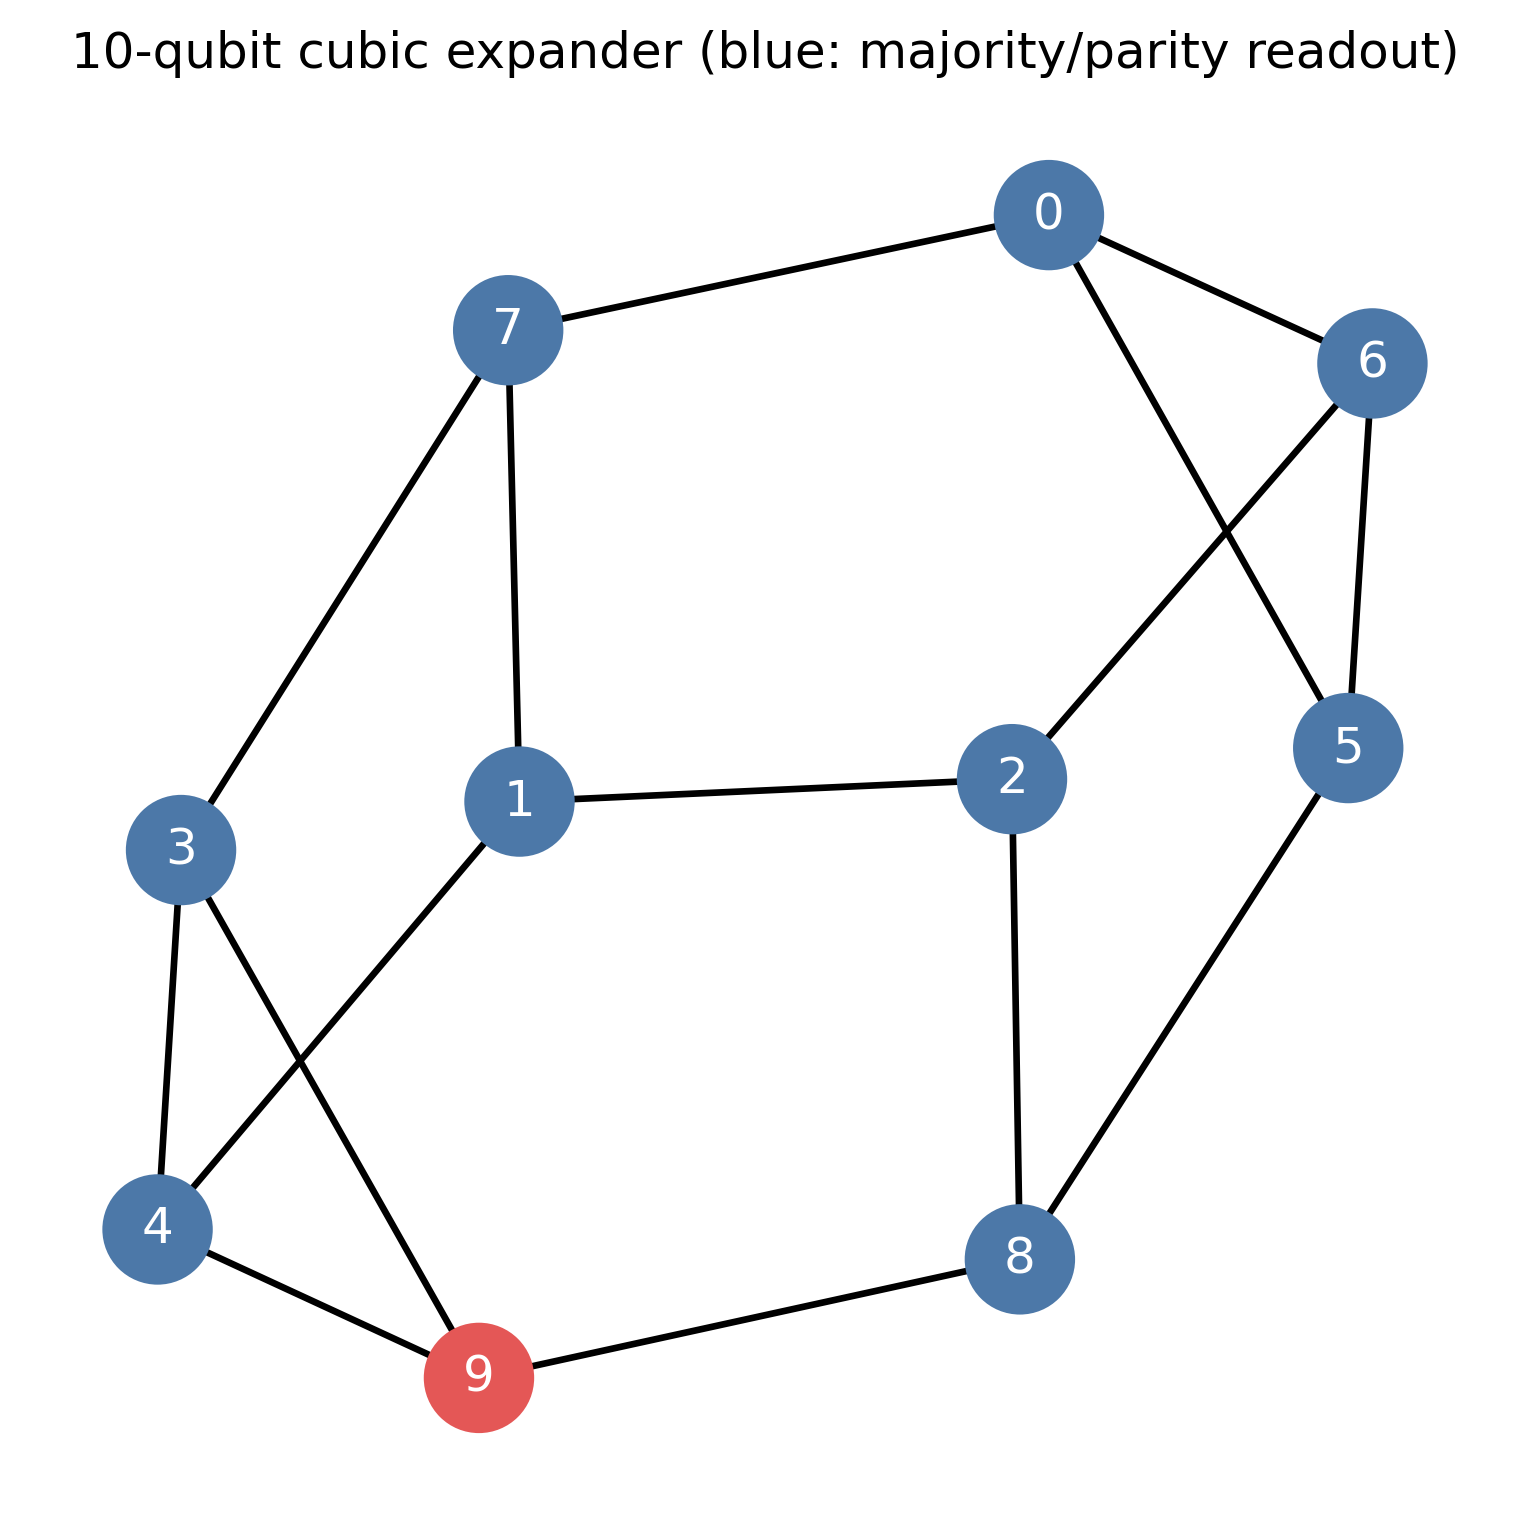

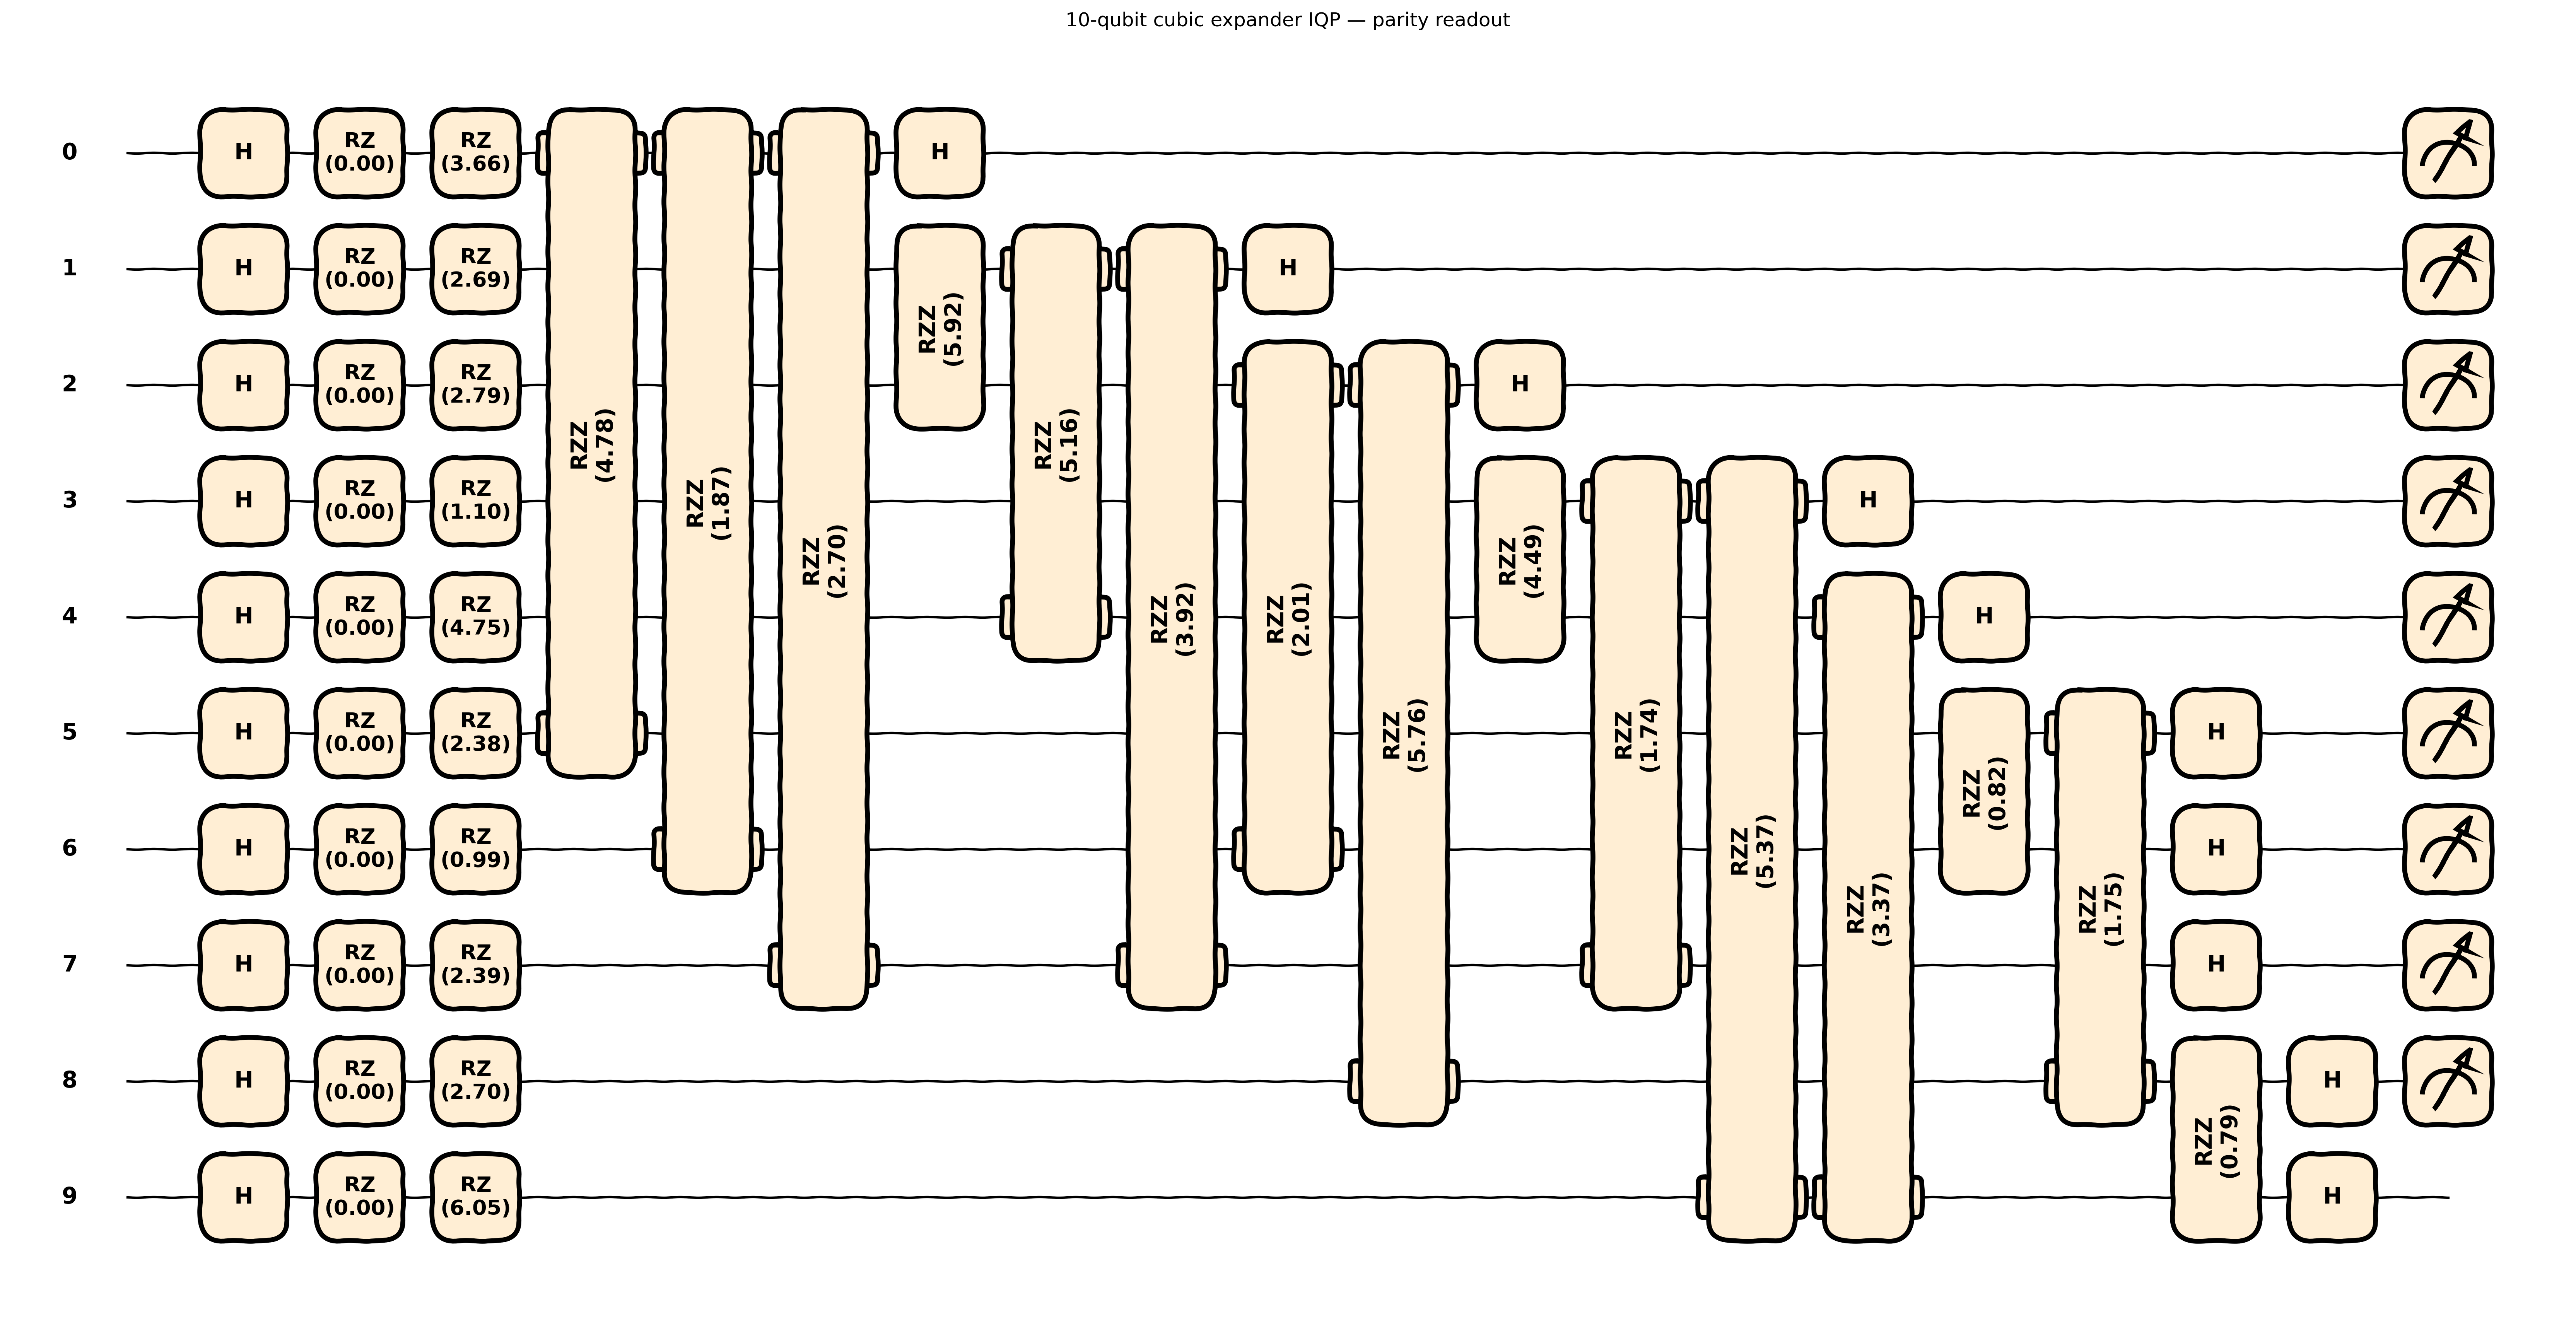

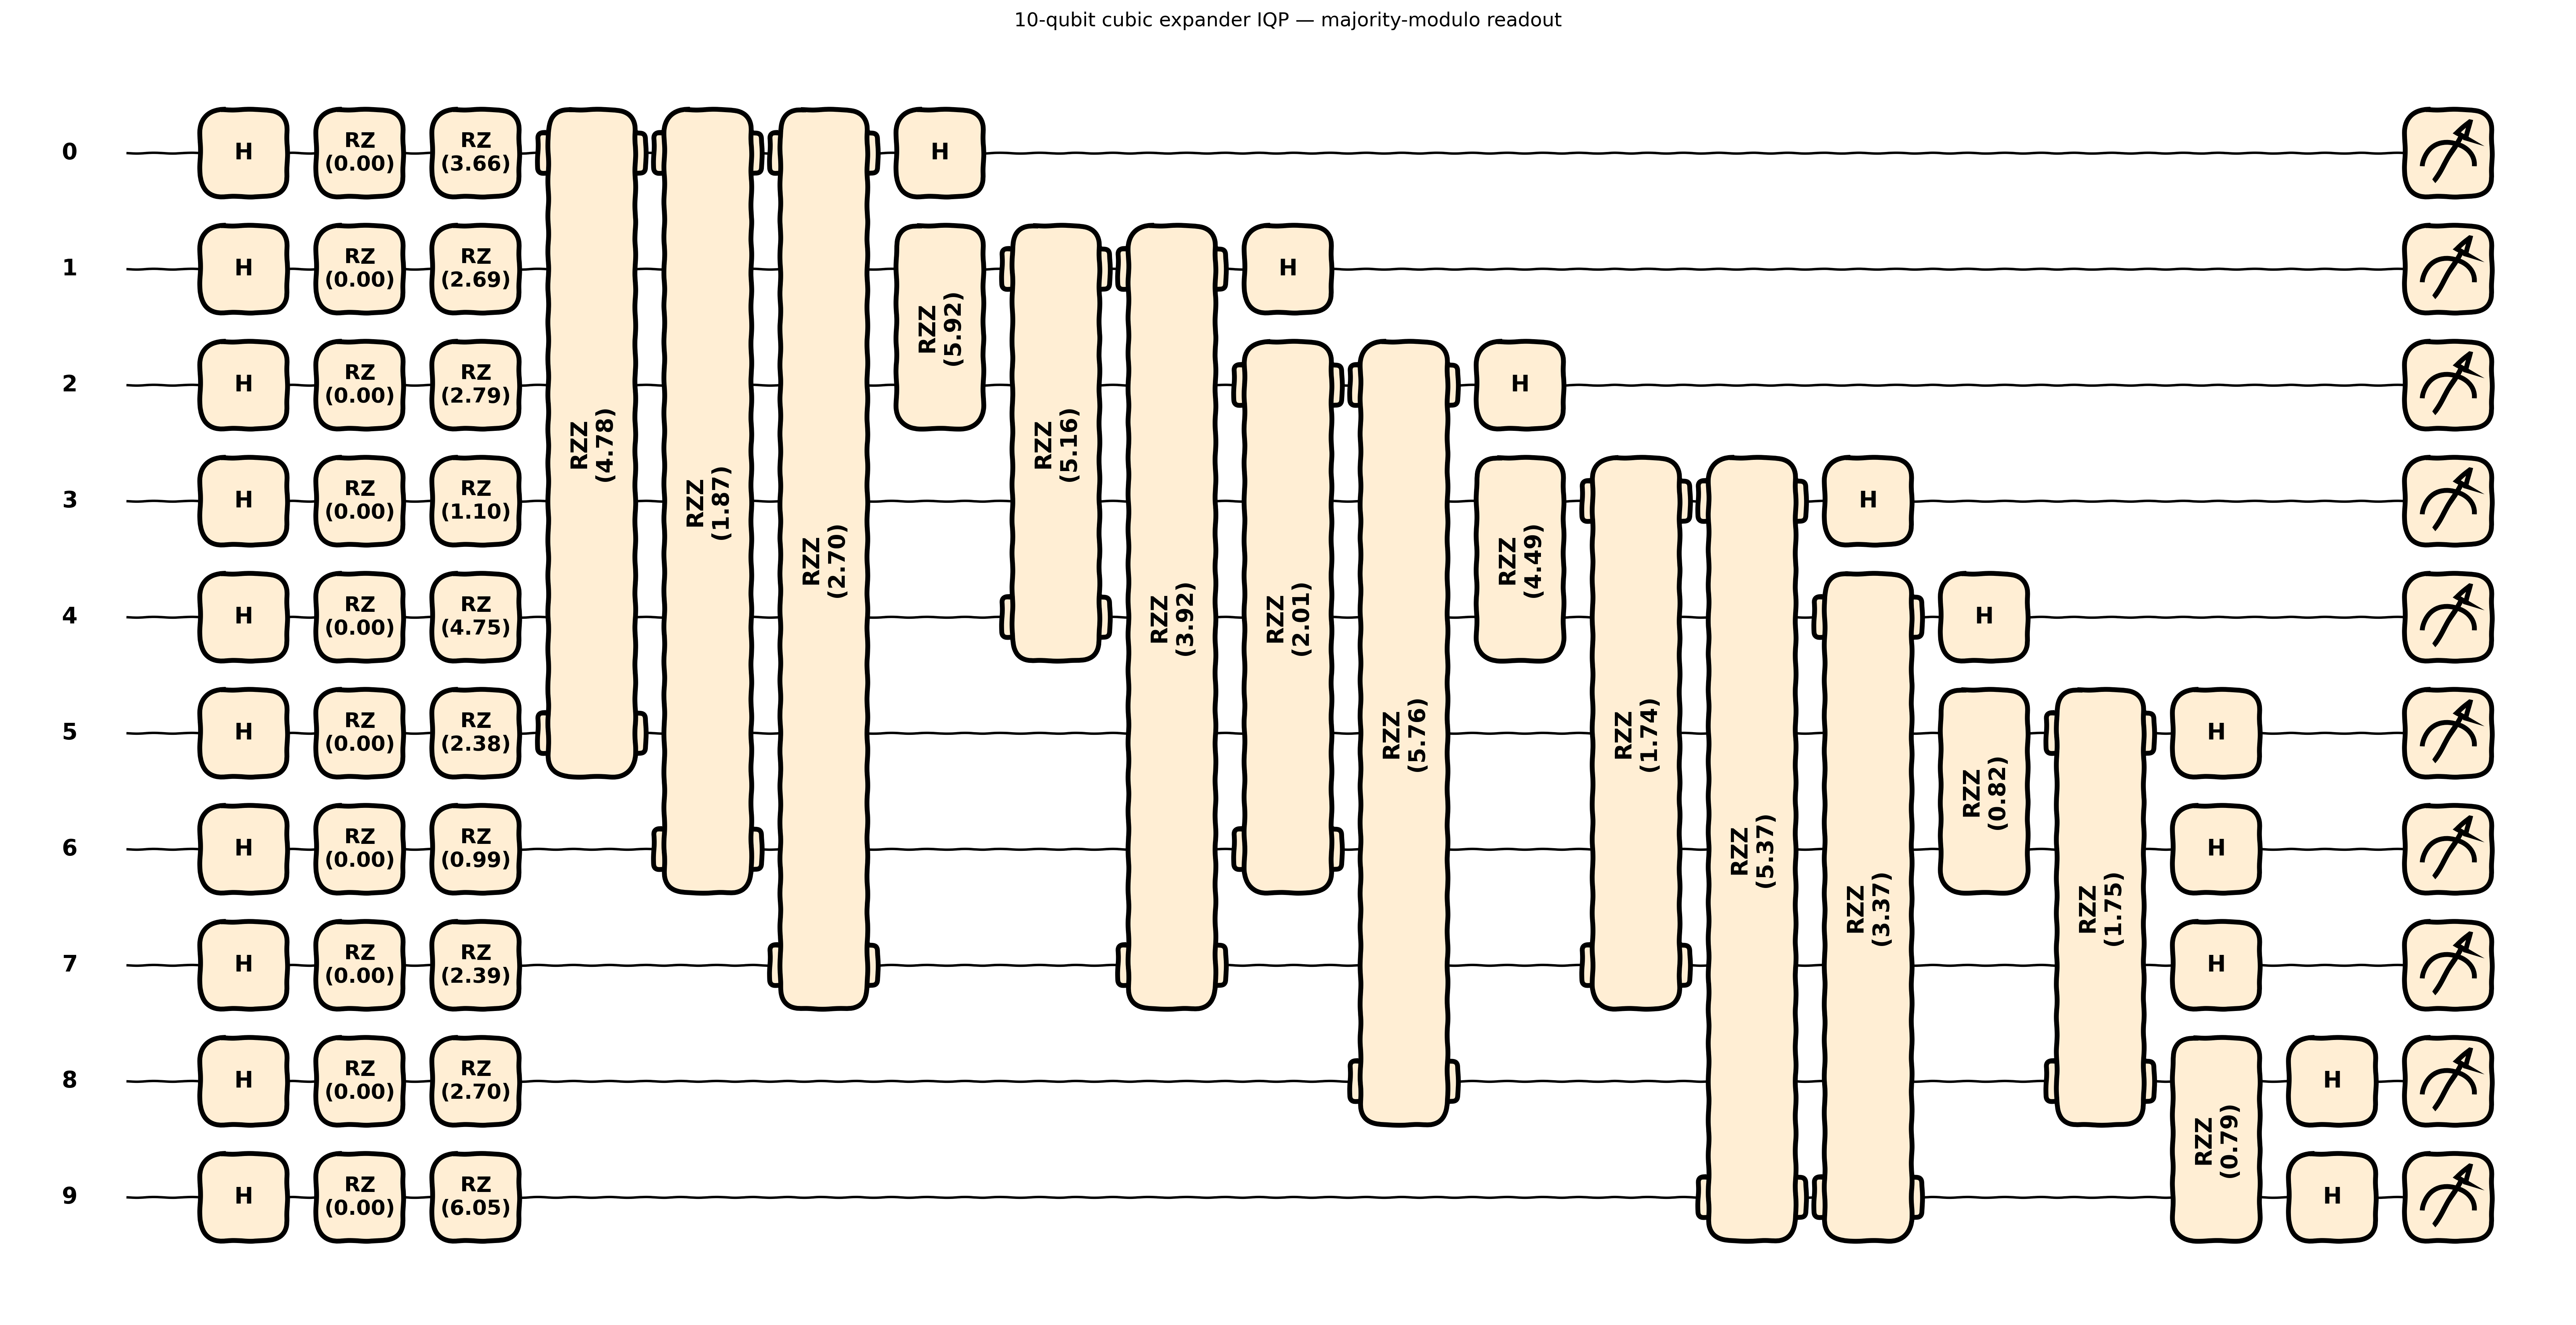

In [4]:
# Draw the graph and a representative one-layer QASP circuit at 300 DPI.
expander_graph = nx.Graph()
expander_graph.add_nodes_from(range(EXPANDER_IQP_N_QUBITS))
expander_graph.add_edges_from(EXPANDER_IQP_EDGES)
expander_positions = nx.spring_layout(
    expander_graph, seed=EXPANDER_IQP_GRAPH_SEED
)
topology_fig, topology_ax = plt.subplots(figsize=(5.2, 5.2), dpi=300)
nx.draw_networkx(
    expander_graph,
    pos=expander_positions,
    node_color=[
        "#4c78a8" if node in EXPANDER_IQP_MEASUREMENT_QUBITS else "#e45756"
        for node in expander_graph.nodes
    ],
    node_size=650,
    width=1.6,
    font_color="white",
    ax=topology_ax,
)
topology_ax.set_title(
    f"{EXPANDER_IQP_GRAPH_LABEL} (blue: majority/parity readout)"
)
topology_ax.set_axis_off()
topology_fig.tight_layout()
plt.show()

parity_expander_iqp, majority_expander_iqp = expander_iqp_parameter_check_models[1]
parity_expander_fig, parity_expander_ax = draw_model(
    model=parity_expander_iqp,
    policy_class="PQCBorn",
    n_qubits=EXPANDER_IQP_N_QUBITS,
    num_inputs=4,
    inputs=torch.zeros(4),
)
parity_expander_fig.set_dpi(300)
parity_expander_fig.suptitle(
    f"{EXPANDER_IQP_GRAPH_LABEL} IQP — parity readout", y=1.02
)
plt.show()

majority_expander_fig, majority_expander_ax = draw_model(
    model=majority_expander_iqp,
    policy_class="PQCBorn",
    n_qubits=EXPANDER_IQP_N_QUBITS,
    num_inputs=4,
    inputs=torch.zeros(4),
)
majority_expander_fig.set_dpi(300)
majority_expander_fig.suptitle(
    f"{EXPANDER_IQP_GRAPH_LABEL} IQP — majority-modulo readout", y=1.02
)
plt.show()

### Matched bounded-degree CartPole experiment

The following cells repeat the matched comparison at one, two, and three layers. Every depth uses five identical initialization seeds for parity and majority-modulo, followed by a joint mean $\pm$ SEM learning-curve plot. The default five-qubit mode has the same Hilbert-space dimension as the earlier experiments; switch to scalable-expander mode only when the stronger graph family is required.

In [5]:
import gc
import time


def make_expander_iqp_cartpole_agent(policy, seed):
    torch.manual_seed(seed)
    np.random.seed(seed)
    agent = REINFORCE(
        policy=policy,
        env_name="CartPole-v1",
        gamma=0.99,
        lr=3e-2,
        batch_episodes=5,
        logits=False,
        normalize_mode="clip",
        normalize_returns=True,
        entropy_coef=5e-3,
        max_steps=200,
        baseline_type="ema",
        baseline_momentum=0.05,
        max_grad_norm=1.0,
    )
    agent.env.reset(seed=seed)
    agent.env.action_space.seed(seed)
    return agent


def run_expander_iqp_layer_sweep(
    n_layers,
    seeds=EXPANDER_IQP_SEEDS,
    num_episodes=EXPANDER_IQP_EPISODES,
):
    layer_results = {
        "parity": [],
        "majority": [],
        "parity_seconds": [],
        "majority_seconds": [],
    }
    for run_index, seed in enumerate(seeds, start=1):
        print(
            f"\n--- {EXPANDER_IQP_GRAPH_LABEL}, L={n_layers}, initialization "
            f"{run_index}/{len(seeds)}, seed={seed} ---"
        )
        parity_policy, majority_policy = make_matched_expander_iqp_policies(
            n_layers=n_layers, seed=seed
        )
        parity_vector = torch.cat(
            [parameter.detach().flatten().cpu() for parameter in parity_policy.parameters()]
        )
        majority_vector = torch.cat(
            [parameter.detach().flatten().cpu() for parameter in majority_policy.parameters()]
        )
        print(
            "parameter check: "
            f"identical={torch.equal(parity_vector, majority_vector)}, "
            f"count={parity_vector.numel()}, L2={parity_vector.norm():.6f}, "
            f"first five={parity_vector[:5].tolist()}"
        )

        for policy_name, policy in (
            ("parity", parity_policy),
            ("majority", majority_policy),
        ):
            agent = make_expander_iqp_cartpole_agent(policy, seed)
            start = time.perf_counter()
            returns = agent.train(num_episodes=num_episodes, log_every=50)
            elapsed = time.perf_counter() - start
            agent.env.close()
            returns = np.asarray(returns, dtype=float)
            layer_results[policy_name].append(returns)
            layer_results[f"{policy_name}_seconds"].append(elapsed)
            print(
                f"{policy_name}: final-20 mean={returns[-20:].mean():.2f}, "
                f"time={elapsed:.1f}s"
            )
        del parity_policy, majority_policy
        gc.collect()

    layer_results["parity"] = np.stack(layer_results["parity"])
    layer_results["majority"] = np.stack(layer_results["majority"])
    return layer_results


expander_iqp_sweep_results = {}

In [6]:
# Sparse-expander IQP: one layer, five matched initializations.
expander_iqp_sweep_results[1] = run_expander_iqp_layer_sweep(n_layers=1)


--- 10-qubit cubic expander, L=1, initialization 1/10, seed=3 ---
parameter check: identical=True, count=65, L2=26.399607, first five=[0.026788488030433655, 0.6633118987083435, 1.7960013151168823, 0.16936218738555908, 2.963240623474121]
Episode 0050 | avg(return_last20) = 20.6 | baseline = ema=10.0
Episode 0100 | avg(return_last20) = 22.8 | baseline = ema=11.2
Episode 0150 | avg(return_last20) = 24.2 | baseline = ema=12.0
Episode 0200 | avg(return_last20) = 18.4 | baseline = ema=10.1
Episode 0250 | avg(return_last20) = 22.2 | baseline = ema=11.5
Episode 0300 | avg(return_last20) = 22.4 | baseline = ema=10.6
Episode 0350 | avg(return_last20) = 30.3 | baseline = ema=13.3
Episode 0400 | avg(return_last20) = 40.9 | baseline = ema=16.8
Episode 0450 | avg(return_last20) = 38.2 | baseline = ema=17.0
Episode 0500 | avg(return_last20) = 46.5 | baseline = ema=19.6
parity: final-20 mean=46.55, time=161.4s
Episode 0050 | avg(return_last20) = 23.6 | baseline = ema=11.4
Episode 0100 | avg(return_la

In [7]:
# Sparse-expander IQP: two layers, five matched initializations.
expander_iqp_sweep_results[2] = run_expander_iqp_layer_sweep(n_layers=2)


--- 10-qubit cubic expander, L=2, initialization 1/10, seed=3 ---
parameter check: identical=True, count=130, L2=38.250546, first five=[0.026788488030433655, 0.6633118987083435, 1.7960013151168823, 0.16936218738555908, 2.963240623474121]
Episode 0050 | avg(return_last20) = 19.1 | baseline = ema=9.9
Episode 0100 | avg(return_last20) = 26.8 | baseline = ema=11.4
Episode 0150 | avg(return_last20) = 24.2 | baseline = ema=11.6
Episode 0200 | avg(return_last20) = 25.7 | baseline = ema=11.6
Episode 0250 | avg(return_last20) = 32.5 | baseline = ema=13.6
Episode 0300 | avg(return_last20) = 34.5 | baseline = ema=14.0
Episode 0350 | avg(return_last20) = 26.2 | baseline = ema=12.1
Episode 0400 | avg(return_last20) = 26.4 | baseline = ema=12.5
Episode 0450 | avg(return_last20) = 26.4 | baseline = ema=12.1
Episode 0500 | avg(return_last20) = 31.2 | baseline = ema=13.3
parity: final-20 mean=31.20, time=151.1s
Episode 0050 | avg(return_last20) = 25.4 | baseline = ema=10.7
Episode 0100 | avg(return_la

In [8]:
# Sparse-expander IQP: three layers, five matched initializations.
expander_iqp_sweep_results[3] = run_expander_iqp_layer_sweep(n_layers=3)


--- 10-qubit cubic expander, L=3, initialization 1/10, seed=3 ---
parameter check: identical=True, count=195, L2=49.162514, first five=[0.026788488030433655, 0.6633118987083435, 1.7960013151168823, 0.16936218738555908, 2.963240623474121]
Episode 0050 | avg(return_last20) = 20.8 | baseline = ema=10.5
Episode 0100 | avg(return_last20) = 28.0 | baseline = ema=12.2
Episode 0150 | avg(return_last20) = 20.4 | baseline = ema=11.1
Episode 0200 | avg(return_last20) = 22.4 | baseline = ema=10.9
Episode 0250 | avg(return_last20) = 24.7 | baseline = ema=11.6
Episode 0300 | avg(return_last20) = 27.9 | baseline = ema=12.9
Episode 0350 | avg(return_last20) = 29.1 | baseline = ema=13.2
Episode 0400 | avg(return_last20) = 22.3 | baseline = ema=11.1
Episode 0450 | avg(return_last20) = 32.0 | baseline = ema=13.3
Episode 0500 | avg(return_last20) = 26.8 | baseline = ema=13.0
parity: final-20 mean=26.75, time=208.4s
Episode 0050 | avg(return_last20) = 28.4 | baseline = ema=12.7
Episode 0100 | avg(return_l

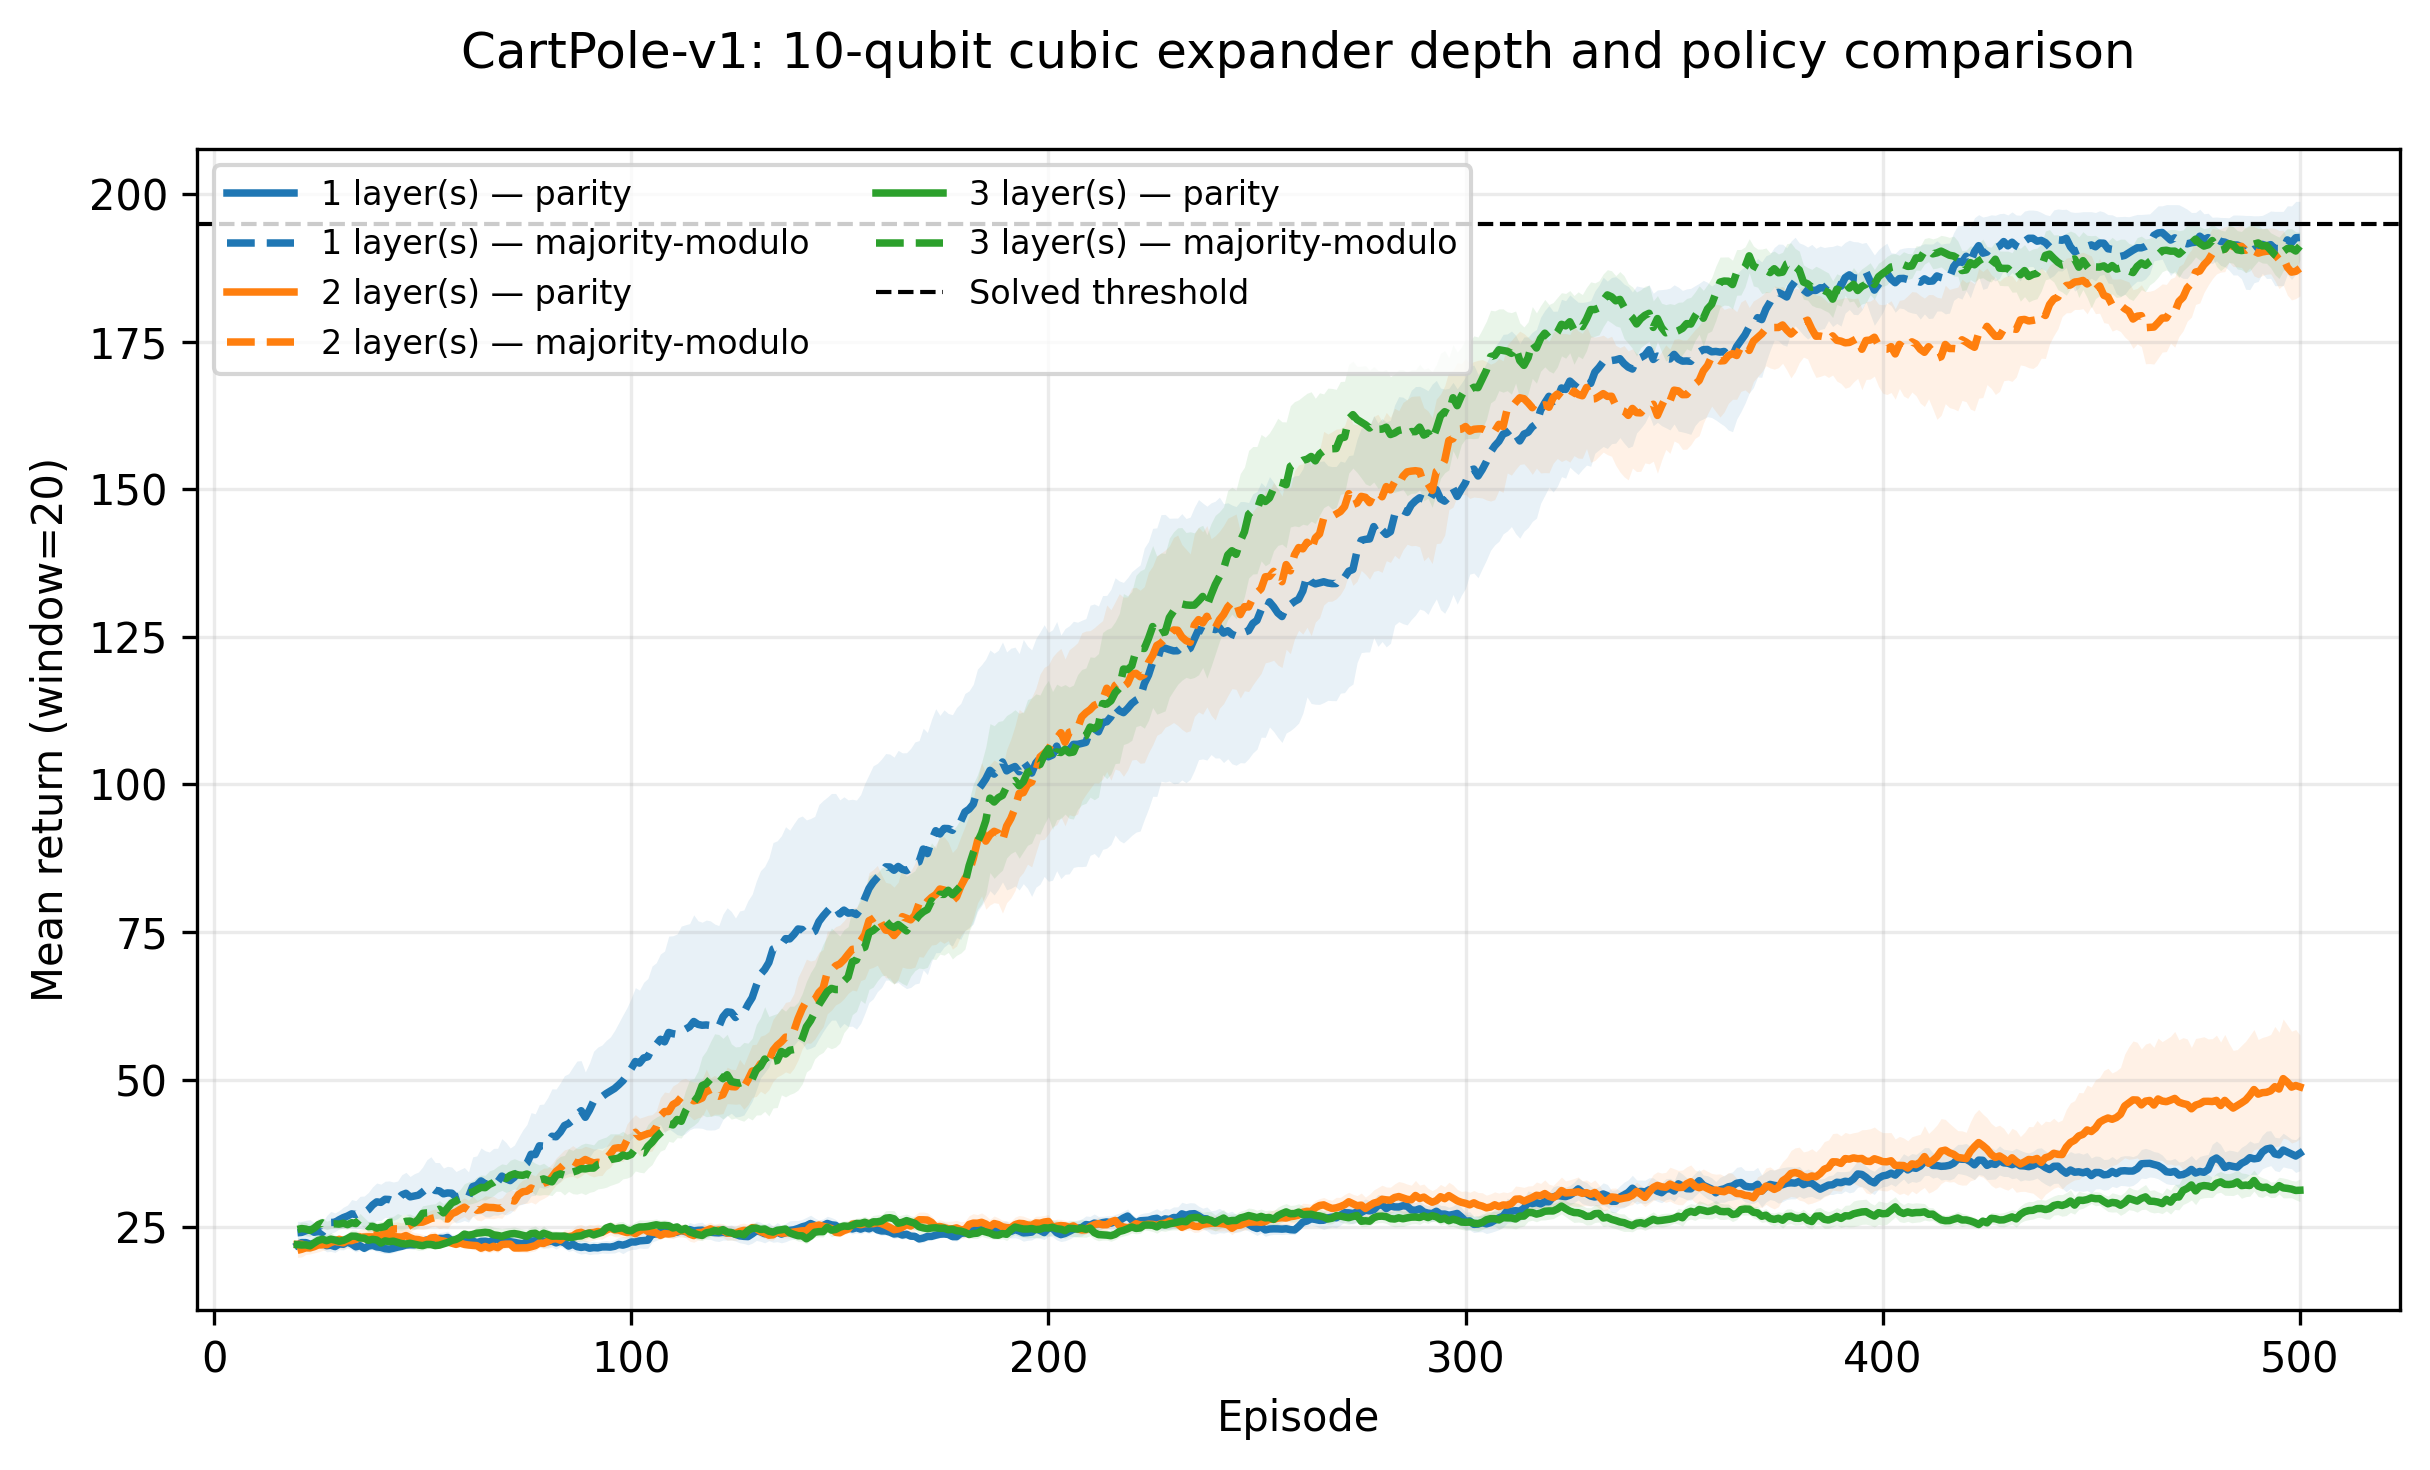

,layers,policy,mean_final_50,sem_final_50,mean_seconds,n_initializations
1,1,majority-modulo,192.130,5.229,419.475,10
0,1,parity,36.634,2.414,106.696,10
3,2,majority-modulo,186.028,4.303,744.712,10
2,2,parity,47.762,9.960,175.990,10
5,3,majority-modulo,190.904,2.363,1140.802,10
4,3,parity,31.046,1.669,226.976,10


In [9]:
# Sparse-expander matched learning curves: mean over five initializations.
import pandas as pd
from IPython.display import display

missing_expander_layers = (
    set(EXPANDER_IQP_LAYERS) - set(expander_iqp_sweep_results)
)
if missing_expander_layers:
    raise RuntimeError(
        f"Run the sparse-expander sweep cells for layers "
        f"{sorted(missing_expander_layers)} before plotting."
    )

expander_window = 20
expander_colors = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}
expander_styles = {"parity": "-", "majority": "--"}
expander_labels = {"parity": "parity", "majority": "majority-modulo"}

expander_fig, expander_ax = plt.subplots(figsize=(8.2, 5.0), dpi=300)
expander_summary_rows = []
for n_layers in EXPANDER_IQP_LAYERS:
    result = expander_iqp_sweep_results[n_layers]
    for policy_name in ("parity", "majority"):
        raw_runs = result[policy_name]
        smoothed_runs = np.stack(
            [
                np.convolve(
                    run, np.ones(expander_window) / expander_window, mode="valid"
                )
                for run in raw_runs
            ]
        )
        mean_curve = smoothed_runs.mean(axis=0)
        sem_curve = smoothed_runs.std(axis=0, ddof=1) / np.sqrt(len(raw_runs))
        episodes = np.arange(expander_window, raw_runs.shape[1] + 1)
        color = expander_colors[n_layers]
        expander_ax.plot(
            episodes,
            mean_curve,
            color=color,
            linestyle=expander_styles[policy_name],
            linewidth=1.8,
            label=f"{n_layers} layer(s) — {expander_labels[policy_name]}",
        )
        expander_ax.fill_between(
            episodes,
            mean_curve - sem_curve,
            mean_curve + sem_curve,
            color=color,
            alpha=0.10,
            linewidth=0,
        )
        final_per_seed = raw_runs[:, -50:].mean(axis=1)
        expander_summary_rows.append(
            {
                "layers": n_layers,
                "policy": expander_labels[policy_name],
                "mean_final_50": final_per_seed.mean(),
                "sem_final_50": (
                    final_per_seed.std(ddof=1) / np.sqrt(len(final_per_seed))
                ),
                "mean_seconds": np.mean(result[f"{policy_name}_seconds"]),
                "n_initializations": len(final_per_seed),
            }
        )

expander_ax.axhline(
    195, color="black", linestyle="--", linewidth=1, label="Solved threshold"
)
expander_ax.set_xlabel("Episode")
expander_ax.set_ylabel(f"Mean return (window={expander_window})")
expander_ax.set_title(
    f"CartPole-v1: {EXPANDER_IQP_GRAPH_LABEL} depth and policy comparison\n"
)
expander_ax.grid(alpha=0.25)
expander_ax.legend(ncol=2, fontsize=8)
expander_fig.tight_layout()
plt.show()

expander_summary_df = pd.DataFrame(expander_summary_rows).sort_values(
    ["layers", "policy"]
)
display(expander_summary_df.round(3))